# EDA de inadimplência

Objetivo:
- Entender como cada variável disponível no cadastro se relaciona com `inadimplente`.
- Quais variáveis são redundantes entre si.
- O que isso implica para as features e os modelos.

Roteiro:

| Seção | Etapa | O que responde |
|---|---|---|
| 1 | Hipóteses | O que esperávamos antes de olhar |
| 2 | Auditoria e alvo | O que temos, quanto falta, quem são as duas populações |
| 3 | Distribuições | Como cada variável se distribui, sozinha |
| 4 | Variáveis vs. alvo | O que separa adimplentes de inadimplentes |
| 5 | Correlação e redundância | O que mede a mesma coisa, e o que mais informa sobre o alvo |
| 6 | Interações | Um sinal muda quando outro está presente? |
| 7 | Tempo | Como os pedidos se distribuem no tempo e se a taxa muda com a safra |
| 8 | Qualidade | Problemas que surgiram durante a EDA |
| 9 | Resumo | Conclusões, hipóteses de features e perguntas em aberto |

Cada gráfico vem entre uma **pergunta** e uma **resposta**.

Note:
- Usa os dados limpos e auditados de `src.dados.carregar_dados_limpos()`.
- As transformações feitas são locais e com intuito de facilitar a leitura e o entendimento: não viram features. 
- Toda taxa por grupo vem com o **n** e um **intervalo de confiança de 95% (Wilson)**: grupos pequenos dão taxas extremas por acaso.

## Glossário

**Taxas e incerteza**

| Termo | Em poucas palavras | Exemplo |
|---|---|---|
| Taxa de inadimplência | % de clientes do grupo que não pagaram | 681 de 2.466 = 27,6% |
| Taxa da base | A taxa de todos os 3.000 clientes. É a linha tracejada dos gráficos | 31,3% |
| `n` | Quantos clientes o grupo tem | `n=12` |
| IC 95% | A margem de erro da taxa: entre quanto e quanto a taxa real deve estar. Quanto menos clientes, maior a margem. É o tracinho preto em cima das barras | 2.466 clientes: 27,6% (de 25,9% a 29,4%). 12 clientes: 66,7% (de 39% a 86%) |
| Wilson | O jeito de calcular o IC. Funciona mesmo com grupos pequenos | — |
| ICs que se cruzam | Se os tracinhos de dois grupos não se cruzam, a diferença é real. Se se cruzam, pode ser acaso | — |

**Distribuições**

| Termo | Em poucas palavras | Exemplo |
|---|---|---|
| Faixa `(a, b]` | De mais de `a` até `b` | `(1300, 1600]` = de 1.301 a 1.600 dias |
| Ponto médio | O meio da faixa | `(0, 25]` → 12,5 |
| Mediana | O valor do meio: metade dos clientes está abaixo, metade acima | — |
| Quartis (Q1, Q3) | Q1: 25% dos clientes estão abaixo. Q3: 75% estão abaixo | 92% não têm protestos, então Q1 = Q3 = 0 |
| IQR | Q3 − Q1. A regra do IQR chama de outlier o que fica longe demais desse miolo | — |
| Outlier | Valor muito fora do padrão. Pode ser erro ou caso raro, mas real | 141 negativações |
| Cauda longa | Quase todos têm valor baixo, e poucos têm valores muito altos | 79% têm 0 negativações, o máximo é 141 |
| Moda | O valor mais comum | — |
| Variância | O quanto os valores se espalham | — |

**Categóricas**

| Termo | Em poucas palavras | Exemplo |
|---|---|---|
| Cardinalidade | Quantos valores diferentes a variável tem | 153 subclasses de CNAE |
| Categoria rara | Menos de 30 clientes. A taxa dela pode sair extrema só por acaso | 138 das 153 subclasses |
| `outros (< 30)` | Onde juntamos as categorias raras | — |
| Nominal / ordinal | Nominal: sem ordem. Ordinal: com ordem | Segmento / faixa de preço (`$` a `$$$$$`) |

**Relação entre variáveis**

| Termo | Em poucas palavras | Escala | Exemplo |
|---|---|---|---|
| Spearman (ρ) | Se uma variável sobe, a outra sobe (ou desce) junto? | −1 a 1. 0 = sem relação | Credores × negativações: 0,90 |
| V de Cramér | O mesmo, para categorias sem ordem | 0 a 1. 0 = sem relação | Divisão × grupo do CNAE: 0,94 |
| Informação mútua (MI) | Quanto saber a variável ajuda a prever quem inadimple | 0 = não ajuda nada. Máximo ~0,62 | Idade do CNPJ: 0,038, a maior |
| Redundância | Duas variáveis que dizem quase a mesma coisa | ρ ou V perto de 1 | Credores e negativações |
| Interação | O efeito de uma variável muda conforme outra | — | Sócio negativado pesa mais em CNPJs de 350 a 5.000 dias |

**Tempo e modelagem**

| Termo | Em poucas palavras | Exemplo |
|---|---|---|
| Safra | Clientes que começaram no mesmo período | Safra de 2022: 2,2% de inadimplência |
| Validação cruzada estratificada | Dividir os dados em partes com a mesma % de inadimplentes em cada uma | — |
| *Target encoding* | Trocar cada categoria pela taxa de inadimplência dela, calculada só no treino | Sugestão para o CNAE |
| ROC-AUC | A chance de um inadimplente sorteado ter score maior que um adimplente sorteado. É a métrica do desafio | 0,5 = sortear; 1 = ordenar perfeitamente. Idade do CNPJ sozinha: ~0,64 |


## Configuração

In [1]:
# Sistema e caminhos
import sys
from pathlib import Path

# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

# Estatística e ML
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Módulos do projeto (src/ fica um nível acima de notebooks/)
sys.path.insert(0, str(Path.cwd().parent))
from src import dados

In [2]:
# Exibição das tabelas
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

# Pasta das figuras
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

# Paleta e estilo dos gráficos
AZUL, LARANJA, CINZA, TEXTO, FUNDO = "#2a78d6", "#eb6834", "#8a8984", "#52514e", "#f0efec"
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, FUNDO, LARANJA])
CMAP_SEQUENCIAL = LinearSegmentedColormap.from_list("seq", [FUNDO, AZUL])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110,
    "text.parse_math": False,  # a faixa de preço do iFood usa "$"
})

In [3]:
# Leitura dos CSVs (dados limpos por src/dados.py)
clientes, pedidos = dados.carregar_dados_limpos()
TAXA_BASE = clientes["inadimplente"].mean()
print(f"clientes: {len(clientes)} | pedidos: {len(pedidos)} | taxa de inadimplência da base: {TAXA_BASE:.1%}")

clientes: 3000 | pedidos: 1977 | taxa de inadimplência da base: 31.3%


### Funções de apoio

Todas foram desenvolvidas localmente. As faixas já chegam de `carregar_dados_limpos()` como categórica ordenada pelo limite inferior, então gráficos e códigos ordinais saem na ordem certa sem tratamento extra.

| Função | Problema que resolve | Entrada → saída | Onde é usada |
|---|---|---|---|
| `ponto_medio` | As estatísticas descritivas (mín, mediana, variância) precisam de um número, não de uma faixa. | Série de faixas → ponto médio de cada faixa. **Escolha local:** na faixa do topo, que tem teto artificial (ex: `(10000000, 100000000000]`), usa o limite inferior. | Seções 2.2 e 3.2 |
| `wilson` | A taxa de um grupo pequeno varia muito por acaso. É preciso mostrar a incerteza. | Nº de inadimplentes `k` e tamanho do grupo `n` → limites inferior e superior do **intervalo de confiança de 95% (Wilson)**. Funciona bem mesmo com `n` pequeno ou taxa perto de 0% ou 100%. | Dentro de `taxa_por_grupo` |
| `taxa_por_grupo` | Calcular a mesma tabela de inadimplência para cada variável. | DataFrame + nome da coluna → tabela com `n`, `inadimplentes`, `taxa`, `ic_inf` e `ic_sup` por grupo. Nulos viram um grupo próprio. `ordenar_por_taxa=True` ordena do menor para o maior risco. | Seções 2.2, 4, 6 e 7 |
| `plot_taxa` | Padronizar os gráficos de taxa por grupo. | Saída de `taxa_por_grupo` → barras com a taxa, barras de erro do IC, rótulo `n=` em cada grupo e a **taxa da base como linha tracejada**. `horizontal=True` para muitos grupos ou rótulos longos. Salva em `reports/figures/` se receber `arquivo`. | Seções 4 e 7 |
| `cramers_v` | Correlação não se aplica a categóricas nominais (segmento, CNAE, fonte...). | Duas séries categóricas → **V de Cramér**, de 0 (independentes) a 1 (uma determina a outra), com correção de viés para não inflar com muitas categorias. | Seção 5.2 |
| `juntar_raros` | Grupos com poucos clientes dão taxas extremas por acaso e inflam as medidas de associação. | Série categórica → mesma série com as categorias de menos de `minimo` clientes (padrão 30, ~1% da base) trocadas por `"outros (< 30)"`. | Seções 4.6, 4.7, 5.2, 5.3 e 5.4 |

In [4]:
def ponto_medio(serie: pd.Series) -> pd.Series:
    lim = dados.limites(serie)
    inf, sup = lim["inf"], lim["sup"]
    topo = inf == inf.max()
    return ((inf + sup) / 2).mask(topo, inf)


def wilson(k, n, z=1.96):
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margem, centro + margem


def taxa_por_grupo(df: pd.DataFrame, col: str, ordenar_por_taxa: bool = False) -> pd.DataFrame:
    tab = df.groupby(col, observed=True, dropna=False)["inadimplente"].agg(n="size", inadimplentes="sum")
    tab["taxa"] = tab["inadimplentes"] / tab["n"]
    tab["ic_inf"], tab["ic_sup"] = wilson(tab["inadimplentes"], tab["n"])
    if ordenar_por_taxa:
        tab = tab.sort_values("taxa")
    return tab


def plot_taxa(tab: pd.DataFrame, titulo: str, arquivo: str | None = None, horizontal: bool = False, xlabel: str = ""):
    rotulos = [str(i) for i in tab.index]
    pos = np.arange(len(tab))
    erro = [tab["taxa"] - tab["ic_inf"], tab["ic_sup"] - tab["taxa"]]
    if horizontal:
        fig, ax = plt.subplots(figsize=(8, 0.32 * len(tab) + 1.2))
        ax.barh(pos, tab["taxa"], color=AZUL, height=0.7)
        ax.errorbar(tab["taxa"], pos, xerr=erro, fmt="none", ecolor=TEXTO, elinewidth=1, capsize=2)
        ax.axvline(TAXA_BASE, color=CINZA, ls="--", lw=1)
        ax.set_yticks(pos, rotulos)
        ax.set_xlabel("taxa de inadimplência (IC 95%)")
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        for y, (t, n) in enumerate(zip(tab["ic_sup"], tab["n"])):
            ax.text(t + 0.015, y, f"n={n}", va="center", fontsize=8, color=TEXTO)
        ax.grid(axis="y", visible=False)
    else:
        fig, ax = plt.subplots(figsize=(max(6, 0.55 * len(tab) + 2), 4))
        ax.bar(pos, tab["taxa"], color=AZUL, width=0.7)
        ax.errorbar(pos, tab["taxa"], yerr=erro, fmt="none", ecolor=TEXTO, elinewidth=1, capsize=2)
        ax.axhline(TAXA_BASE, color=CINZA, ls="--", lw=1)
        ax.set_xticks(pos, rotulos, rotation=45, ha="right")
        ax.set_ylabel("taxa de inadimplência (IC 95%)")
        ax.set_xlabel(xlabel)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        for x, (t, n) in enumerate(zip(tab["ic_sup"], tab["n"])):
            ax.text(x, t + 0.01, f"n={n}", ha="center", fontsize=7, color=TEXTO)
        ax.grid(axis="x", visible=False)
    ax.set_title(titulo, loc="left", fontsize=11)
    plt.tight_layout()
    if arquivo:
        plt.savefig(FIG / arquivo, dpi=150)
    plt.show()


def cramers_v(a: pd.Series, b: pd.Series) -> float:
    tab = pd.crosstab(a, b)
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(kc - 1, rc - 1)))


def juntar_raros(s: pd.Series, minimo: int = 30, rotulo: str = "outros (< 30)") -> pd.Series:
    return s.where(s.map(s.value_counts()) >= minimo, rotulo)

### Colunas derivadas para a análise (só leitura)

O DataFrame `aux` guarda versões tratadas de colunas de `clientes` que aparecem em várias seções. São calculadas uma vez aqui e reaproveitadas depois. Não alteram `clientes` e não viram features do modelo.

| Coluna de `aux` | O que é | Por que existe |
|---|---|---|
| `tem_ifood` | `True` se o estabelecimento está no iFood, `False` se não está | No original não existe essa coluna: quem não está no iFood só tem os campos do iFood vazios |
| `tem_google_maps` | `True` se o estabelecimento está no Google Maps, `False` se não está | Mesmo caso: quem não está no Maps tem os campos do Maps vazios |
| `tem_credores_serasa` | `True` se o cliente deve a alguma empresa segundo a Serasa, `False` se não deve | Em `serasa_credores`, vazio significa que não deve a ninguém |
| `n_credores` | Quantos credores estão listados em `serasa_credores` | O original é uma lista em texto |
| `cnae_divisao`, `cnae_grupo`, `cnae_classe` | Os níveis do CNAE acima da subclasse: divisão (2 dígitos, ex: `56`), grupo (3 dígitos, ex: `56.1`) e classe (4 dígitos + dígito verificador, ex: `56.11-2`) | A subclasse tem 153 valores, quase todos raros |
| `municipio_agrup`, `cnae_grupo_agrup`, `cnae_classe_agrup` | Município, grupo e classe do CNAE com as categorias de menos de 30 clientes juntadas em "outros" (`juntar_raros`) | Evita taxas extremas por grupos minúsculos |
| `populacao` | "com pedidos" ou "sem pedidos" | Para comparar as duas populações (seção 2.2) |

In [5]:
aux = pd.DataFrame(index=clientes.index)
aux["tem_ifood"] = clientes[["ifood_contagem_avaliacoes", "ifood_faixa_preco"]].notna().any(axis=1)
aux["tem_google_maps"] = clientes["google_maps_contagem_avaliacoes"].notna()
aux["tem_credores_serasa"] = clientes["serasa_credores"].notna()
credores = clientes["serasa_credores"].str.split(",")
aux["n_credores"] = credores.map(lambda l: len(l) if isinstance(l, list) else 0)
aux["cnae_divisao"] = clientes["cnae_codigo"].str[:2]
aux["cnae_grupo"] = clientes["cnae_codigo"].str[:4]
aux["cnae_classe"] = clientes["cnae_codigo"].str[:7]
aux["municipio_agrup"] = juntar_raros(clientes["municipio"])
aux["cnae_grupo_agrup"] = juntar_raros(aux["cnae_grupo"])
aux["cnae_classe_agrup"] = juntar_raros(aux["cnae_classe"])
aux["populacao"] = clientes["id_cliente"].isin(pedidos["id_cliente"]).map({True: "com pedidos", False: "sem pedidos"})

## 1. Hipóteses

O que se espera antes de ter conhecimento real sobre os dados?

| # | Variável | Hipótese | Por quê |
|---|---|---|---|
| H1 | `idade_cnpj` | Inadimplência cai com a idade do CNPJ | Empresa que sobrevive mais tempo tende a ter caixa mais estável (o enunciado sugere isso a partir de ~2.400 dias) |
| H2 | `capital_social` | Inadimplência cai com o capital social | Mais capital = mais folga para pagar |
| H3 | Serasa (negativações, protestos, credores, sócio negativado) | Quem tem registro na Serasa inadimple mais | Inadimplência passada prevê inadimplência futura |
| H4 | Presença em iFood / Google Maps | Quem está nas plataformas inadimple menos | Negócio mais estruturado e com mais visibilidade |
| H5 | Avaliações no iFood / Google Maps | Mais avaliações = menos inadimplência | Proxy de volume de vendas |
| H6 | `natureza_juridica` | Empresário individual inadimple mais que LTDA | Menos separação entre finanças pessoais e da empresa |
| H7 | `fonte_cliente` | A taxa varia com a fonte de aquisição | Canais diferentes trazem perfis diferentes |
| H8 | `segmento_cliente` / CNAE | Alguns segmentos são bem mais arriscados | Margem e sazonalidade variam por atividade |
| H9 | `municipio` | Capital (Fortaleza) e interior têm taxas diferentes | Perfil de varejo e acesso a crédito diferentes |
| H10 | Histórico de pedidos (`atraso`, `valor`) | Quem atrasa mais inadimple mais | Atraso passado é o sinal mais direto de dificuldade para pagar (o enunciado sugere a % de pedidos com atraso) |

## 2. Auditoria e alvo

### 2.1 Dicionário de dados

Tipo, nulos e cardinalidade vêm de `dados.relatorio_qualidade`.

O significado do nulo e os problemas conhecidos vêm do notebook 01 e da documentação da Praso.

In [6]:
significado = {
    "id_cliente": ("chave", "—"),
    "uf": ("categórica", "constante: todos são do CE"),
    "municipio": ("categórica", "64% em Fortaleza; 23 de 36 com < 30 clientes"),
    "segmento_cliente": ("categórica", "anonimizado (Segmento 1–21)"),
    "natureza_juridica": ("categórica", "3 das 5 categorias têm ≤ 12 clientes"),
    "fonte_cliente": ("categórica", "anonimizada; Fontes 3 e 4 têm 7 e 2 clientes"),
    "cnae_codigo": ("categórica hierárquica", "153 subclasses, 138 com < 30 clientes"),
    "capital_social": ("faixa", "teto artificial na última faixa"),
    "idade_cnpj": ("faixa (dias)", "teto artificial na última faixa"),
    "serasa_contagem_negativacoes": ("contagem", "cauda longa (máx. 141)"),
    "serasa_contagem_protestos": ("contagem", "cauda longa (máx. 79)"),
    "serasa_credores": ("lista de segmentos", "nulo = sem credores; 5 clientes com > 5 listados"),
    "serasa_socio_tem_negativacao": ("binária", "—"),
    "ifood_contagem_avaliacoes": ("faixa", "nulo = não está no iFood"),
    "ifood_faixa_preco": ("ordinal ($–$$$$$)", "nulo = não está no iFood; 177 com faixa e sem contagem"),
    "google_maps_avaliacao": ("faixa (0–5)", "só 34 valores"),
    "google_maps_contagem_avaliacoes": ("faixa", "nulo = não está no Maps"),
    "google_maps_tem_website": ("binária", "só 1 ou nulo"),
    "inadimplente": ("alvo", "—"),
}
dicionario = dados.relatorio_qualidade(clientes)
dicionario[["natureza", "problemas conhecidos"]] = pd.DataFrame.from_dict(significado, orient="index")
dicionario

,tipo,nulos,pct_nulos,valores_distintos,natureza,problemas conhecidos
id_cliente,int64,0,0.000,3000,chave,—
uf,str,0,0.000,1,categórica,constante: todos são do CE
municipio,str,0,0.000,36,categórica,64% em Fortaleza; 23 de 36 com < 30 clientes
segmento_cliente,str,0,0.000,21,categórica,anonimizado (Segmento 1–21)
natureza_juridica,str,0,0.000,5,categórica,3 das 5 categorias têm ≤ 12 clientes
fonte_cliente,str,0,0.000,5,categórica,anonimizada; Fontes 3 e 4 têm 7 e 2 clientes
cnae_codigo,str,0,0.000,153,categórica hierárquica,"153 subclasses, 138 com < 30 clientes"
capital_social,category,0,0.000,19,faixa,teto artificial na última faixa
idade_cnpj,category,0,0.000,20,faixa (dias),teto artificial na última faixa
serasa_contagem_negativacoes,int64,0,0.000,36,contagem,cauda longa (máx. 141)


### 2.2 Alvo e as duas populações

O alvo tem 31,3% de inadimplentes, que é um desbalanceamento moderado, sendo passível de um split estratificado e ROC-AUC, mas não necessita reamostragem obrigatória.

#### **Pergunta:** Os clientes com pedidos (que entram no modelo comportamental) se parecem com os sem pedidos?

In [7]:
taxa_por_grupo(aux.assign(inadimplente=clientes["inadimplente"]), "populacao")

,n,inadimplentes,taxa,ic_inf,ic_sup
populacao,,,,,
com pedidos,664,138,0.208,0.179,0.240
sem pedidos,2336,802,0.343,0.324,0.363


In [8]:
perfil = pd.DataFrame({
    "inadimplência": clientes["inadimplente"],
    "idade do CNPJ (mediana, dias)": ponto_medio(clientes["idade_cnpj"]),
    "sócio negativado": clientes["serasa_socio_tem_negativacao"],
    "tem credores na Serasa": aux["tem_credores_serasa"],
    "LTDA": clientes["natureza_juridica"].str.startswith("206-2"),
    "Fonte 1": clientes["fonte_cliente"].eq("Fonte 1"),
    "está no iFood": aux["tem_ifood"],
    "está no Google Maps": aux["tem_google_maps"],
    "Fortaleza": clientes["municipio"].eq("FORTALEZA"),
}).groupby(aux["populacao"])
comparacao = perfil.mean().T
comparacao.loc["idade do CNPJ (mediana, dias)"] = perfil["idade do CNPJ (mediana, dias)"].median()
comparacao

populacao,com pedidos,sem pedidos
inadimplência,0.208,0.343
"idade do CNPJ (mediana, dias)",1450.000,1225.000
sócio negativado,0.468,0.478
tem credores na Serasa,0.140,0.189
LTDA,0.327,0.222
Fonte 1,0.652,0.694
está no iFood,0.172,0.107
está no Google Maps,0.098,0.061
Fortaleza,0.642,0.646


**Resposta:** Não. Os clientes com pedidos inadimplem bem menos: **20,8%** contra **34,3%** (ICs sem sobreposição). Mas o perfil de cadastro das duas populações é parecido. A proporção de sócio negativado (47% vs 48%) e de Fortaleza (64% vs 65%) é quase igual. Os com pedidos são um pouco mais velhos (mediana de 1.450 vs 1.225 dias), mais LTDA (33% vs 22%) e com menos credores na Serasa (14% vs 19%).

Essas diferenças pequenas dificilmente explicam 13,5 pontos de diferença na taxa. A hipótese mais provável é que o alvo foi definido de forma diferente para quem nunca comprou (pergunta em aberto 2). Consequência para o modelo comportamental: o ganho dele deve ser medido só nos 664 clientes com pedidos, comparando com o modelo de aplicação **nos mesmos 664**.

## 3. Distribuições

O notebook dará início à **análise univariada**.

Cada feature será analisada individualmente no dataset, ainda sem cruzar com a inadimplência, para entender sua distribuição, concentração e categorias raras.

### 3.1 Variáveis em faixas

As contínuas vêm em faixas, então o equivalente ao histograma é a contagem por faixa. Para iFood e Google Maps, só quem está na plataforma.

#### **Pergunta:** Como se distribuem as variáveis em faixas? Alguma é bimodal ou concentrada demais para ser útil?

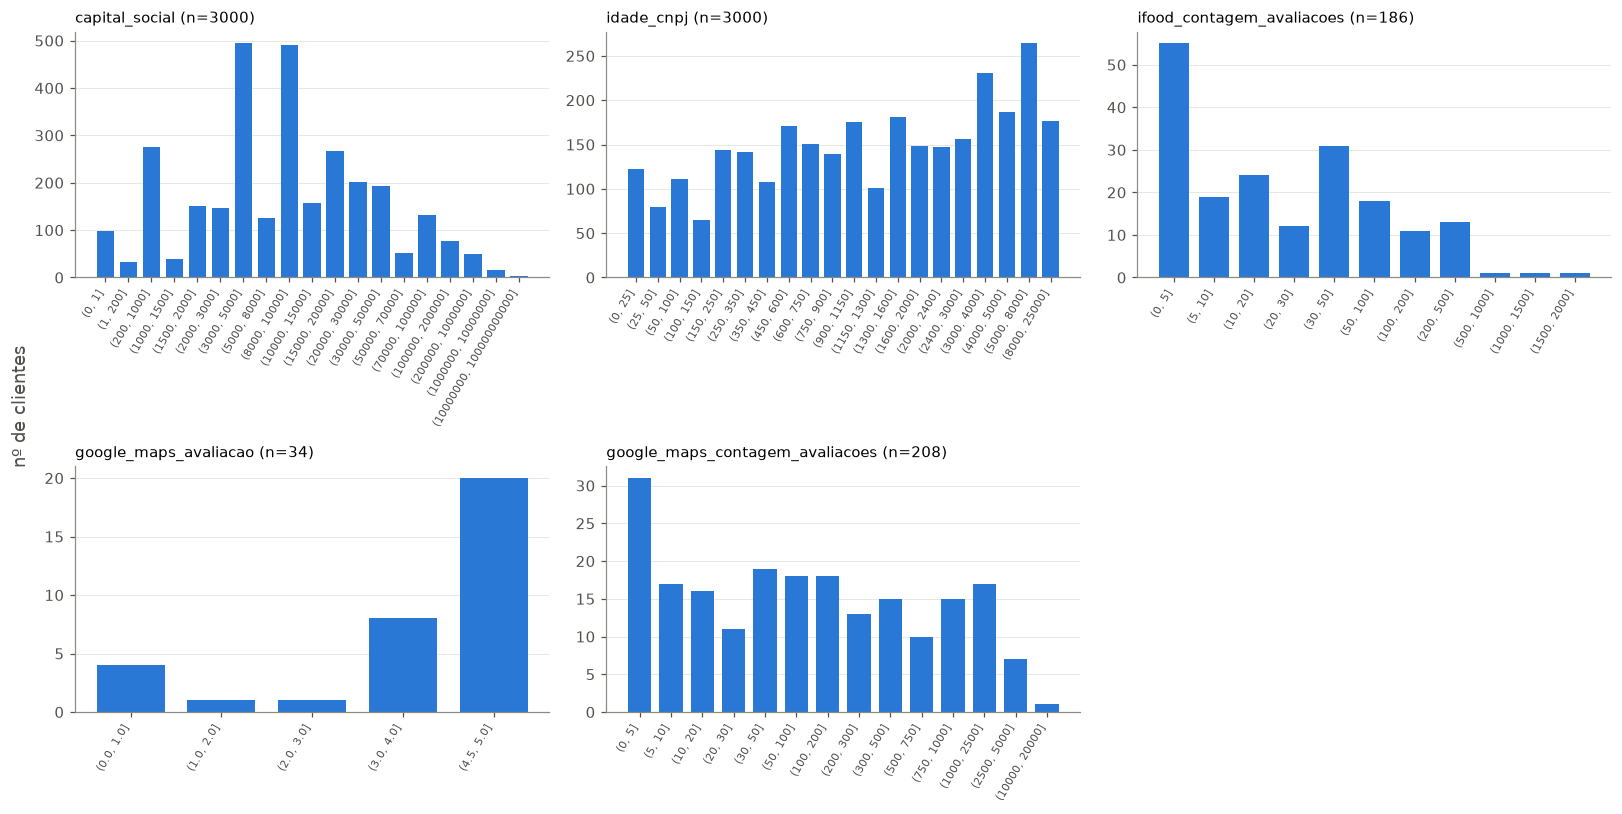

In [9]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, col in zip(eixos.flat, dados.INTERVALOS_CLIENTES):
    cont = clientes[col].value_counts(sort=False)
    ax.bar(range(len(cont)), cont.values, color=AZUL, width=0.75)
    ax.set_xticks(range(len(cont)), [str(i) for i in cont.index], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{col} (n={cont.sum()})", loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
eixos.flat[-1].axis("off")
fig.supylabel("nº de clientes", color=TEXTO)
plt.tight_layout(); plt.savefig(FIG / "eda_distribuicao_faixas.png", dpi=150); plt.show()

**Resposta:**
- **`capital_social`:** concentrado em valores redondos declarados no registro. As faixas (3.000, 5.000] e (8.000, 10.000] têm ~490 clientes cada.

- **`idade_cnpj`:** espalhada, com mais clientes nas faixas acima de 3.000 dias (~8 anos).

- **`contagem_avaliacoes`**: tanto em Google Maps quanto em iFood:  cauda longa, com a maior faixa em (0, 5].

- **`google_maps_avaliacao`**: só 34 valores, 20 deles em (4,5; 5,0]. Concentrada demais e rara demais para ser útil.

Não há feature de avaliação (nota) do iFood nos dados: do iFood só temos o número de avaliações e a faixa de preço. A nota existe apenas para o Google Maps.

As faixas têm larguras diferentes, então a altura das barras compara clientes por faixa, não densidade. Nenhuma distribuição é bimodal de forma que indique duas subpopulações.

### 3.2 Estatísticas descritivas por alvo

Calculadas sobre o ponto médio das faixas (topo = limite inferior). A moda é a faixa mais frequente. As colunas de iFood e Google Maps só contam quem está na plataforma.

In [10]:
linhas = []
for col in dados.INTERVALOS_CLIENTES:
    num = ponto_medio(clientes[col])
    for alvo, nome in [(0, "adimplente"), (1, "inadimplente")]:
        m = clientes["inadimplente"] == alvo
        s = num[m].dropna()
        linhas.append({
            "variável": col, "grupo": nome, "n": len(s),
            "mín": s.min(), "mediana": s.median(), "máx": s.max(), "variância": s.var(),
            "moda (faixa)": clientes.loc[m, col].mode().iloc[0] if s.size else None,
        })
pd.DataFrame(linhas).set_index(["variável", "grupo"])

n    mín  mediana  \
variável                        grupo                                
capital_social                  adimplente    2060  0.500 9000.000   
                                inadimplente   940  0.500 6500.000   
idade_cnpj                      adimplente    2060 12.500 1800.000   
                                inadimplente   940 12.500  825.000   
ifood_contagem_avaliacoes       adimplente     133  2.500   15.000   
                                inadimplente    53  2.500   15.000   
google_maps_avaliacao           adimplente      24  0.500    4.500   
                                inadimplente    10  3.500    4.500   
google_maps_contagem_avaliacoes adimplente     154  2.500  150.000   
                                inadimplente    54  2.500   40.000   

                                                      máx        variância  \
variável                        grupo                                        
capital_social                  adimplente   10000000.000 428020326581.532   
                                inadimplente   600000.000   7201623079.967   
idade_cnpj                      adimplente       8000.000      6470061.264   
                                inadimplente     8000.000      2897925.889   
ifood_contagem_avaliacoes       adimplente       1500.000        23739.172   
                                inadimplente     1250.000        43968.668   
google_maps_avaliacao           adimplente          4.500            2.341   
                                inadimplente        4.500            0.233   
google_maps_contagem_avaliacoes adimplente      10000.000      1375320.357   
                                inadimplente      625.000        30657.329   

                                               moda (faixa)  
variável                        grupo                        
capital_social                  adimplente    (8000, 10000]  
                                inadimplente   (3000, 5000]  
idade_cnpj                      adimplente     (5000, 8000]  
                                inadimplente     (450, 600]  
ifood_contagem_avaliacoes       adimplente           (0, 5]  
                                inadimplente         (0, 5]  
google_maps_avaliacao           adimplente       (4.5, 5.0]  
                                inadimplente     (4.5, 5.0]  
google_maps_contagem_avaliacoes adimplente           (0, 5]  
                                inadimplente         (0, 5]

### 3.3 Contagens da Serasa e outliers

A regra do **IQR** (*abaixo de [Q1 − 1,5.IQR] ou acima de [Q3 + 1,5.IQR]*) não serve aqui: a maioria dos clientes tem zero, então Q1 = Q3 = 0 e qualquer registro vira "outlier". Os valores altos são plausíveis (dívidas acumuladas), não erros.

In [11]:
q = clientes[["serasa_contagem_negativacoes", "serasa_contagem_protestos"]].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).T
q["% com > 0"] = (clientes[q.index] > 0).mean()
q["% marcado pelo IQR"] = [
    (clientes[c] > clientes[c].quantile(0.75) + 1.5 * (clientes[c].quantile(0.75) - clientes[c].quantile(0.25))).mean()
    for c in q.index
]
q

,0.250,0.500,0.750,0.900,0.990,% com > 0,% marcado pelo IQR
serasa_contagem_negativacoes,0.000,0.000,0.000,2.000,15.010,0.210,0.210
serasa_contagem_protestos,0.000,0.000,0.000,0.000,6.010,0.077,0.077


### 3.4 Categóricas: cardinalidade e categorias raras

Categoria rara = menos de 1% das linhas (30 clientes).

É possível que elas sumam de um fold da validação cruzada e gerem taxas extremas caso não seja estratificado.

In [12]:
categoricas = ["municipio", "segmento_cliente", "natureza_juridica", "fonte_cliente", "cnae_codigo"]
extra = {"cnae divisão": aux["cnae_divisao"], "cnae grupo": aux["cnae_grupo"], "cnae classe": aux["cnae_classe"]}
linhas = []
for nome, s in [*((c, clientes[c]) for c in categoricas), *extra.items()]:
    cont = s.value_counts()
    raras = cont[cont < 0.01 * len(s)]
    linhas.append({
        "variável": nome, "valores distintos": len(cont), "categorias raras (< 1%)": len(raras),
        "% de clientes em categorias raras": raras.sum() / len(s), "maior categoria (% da base)": cont.iloc[0] / len(s),
    })
pd.DataFrame(linhas).set_index("variável")

,valores distintos,categorias raras (< 1%),% de clientes em categorias raras,maior categoria (% da base)
variável,,,,
municipio,36,23,0.043,0.645
segmento_cliente,21,5,0.024,0.204
natureza_juridica,5,3,0.005,0.750
fonte_cliente,5,2,0.003,0.685
cnae_codigo,153,138,0.167,0.230
cnae divisão,39,36,0.077,0.473
cnae grupo,83,73,0.098,0.381
cnae classe,111,100,0.131,0.381


**Resposta:** 
- **Subclasse de CNAE:** 138 das 153 subclasses são raras e juntas somam 16,7% dos clientes. Não é muito viável usá-la direto.

- **Níveis acima da subclasse:** 3 divisões cobrem 92% da base, mas são grossas demais. O grupo (10 com n ≥ 30, 90% da base) e a classe (11 com n ≥ 30, 87% da base) são meios-termos melhores.

- **Dígito verificador da classe:** no CNAE real, os 4 primeiros dígitos já definem a classe. Na base anonimizada, 5 classes aparecem com dois dígitos verificadores (ex: `77.36-5` com 39 clientes e `77.36-6` com 1). Por isso a classe aqui usa o código com o dígito (`56.11-2`): são 111 valores, e não 106.

- **Município:** 23 dos 36 são raros, mas eles somam só 4,3% dos clientes.

- **Natureza jurídica e fonte:** as categorias raras somam menos de 1% dos clientes. Juntar em "outros" resolve.

- **Categorias dominantes:** natureza jurídica (75% empresário individual) e fonte (69% Fonte 1).

**Como o CNAE é organizado**

O CNAE (Classificação Nacional de Atividades Econômicas, do IBGE) é hierárquico: cada nível detalha o anterior. Com o exemplo do enunciado, `56.11-2-01`, pelo CNAE real:

| Nível | Código | Atividade |
|---|---|---|
| Seção | I | Alojamento e alimentação |
| Divisão | `56` | Alimentação |
| Grupo | `56.1` | Restaurantes e outros serviços de alimentação e bebidas |
| Classe | `56.11-2` | Restaurantes e outros estabelecimentos de serviços de alimentação e bebidas |
| Subclasse | `56.11-2-01` | Restaurantes e similares |

A subclasse é o nível mais fino: na mesma classe `56.11-2` também estão `56.11-2-03` (lanchonetes, casas de chá, de sucos e similares) e `56.11-2-04` (bares sem entretenimento). A seção (a letra) não faz parte do código.

Na base, os códigos foram anonimizados, mas a hierarquia foi mantida. Em `77.49-8-16`, por exemplo, a divisão é `77`, o grupo `77.4`, a classe `77.49-8` e a subclasse `77.49-8-16`. A atividade real não pode ser recuperada: a divisão `77` da base não é a divisão 77 do IBGE.

**Diferença em relação ao enunciado:** a descrição do desafio chama `56.11` de grupo e `56.11-2` de classe. Este notebook segue o IBGE, em que o grupo tem 3 dígitos (`56.1`). Na prática, o "grupo" do enunciado (`56.11`) é a classe sem o dígito verificador, então a análise de classe daqui cobre os dois.


## 4. Variáveis vs. alvo

Aqui se inicia a **análise bivariada**.
Cada variável é cruzada com a inadimplência, uma de cada vez, para ver o que separa adimplentes de inadimplentes.

### 4.1 Idade do CNPJ (Gráfico 1 do enunciado)

#### **Pergunta:** A inadimplência cai com a idade do CNPJ? A partir de quando?

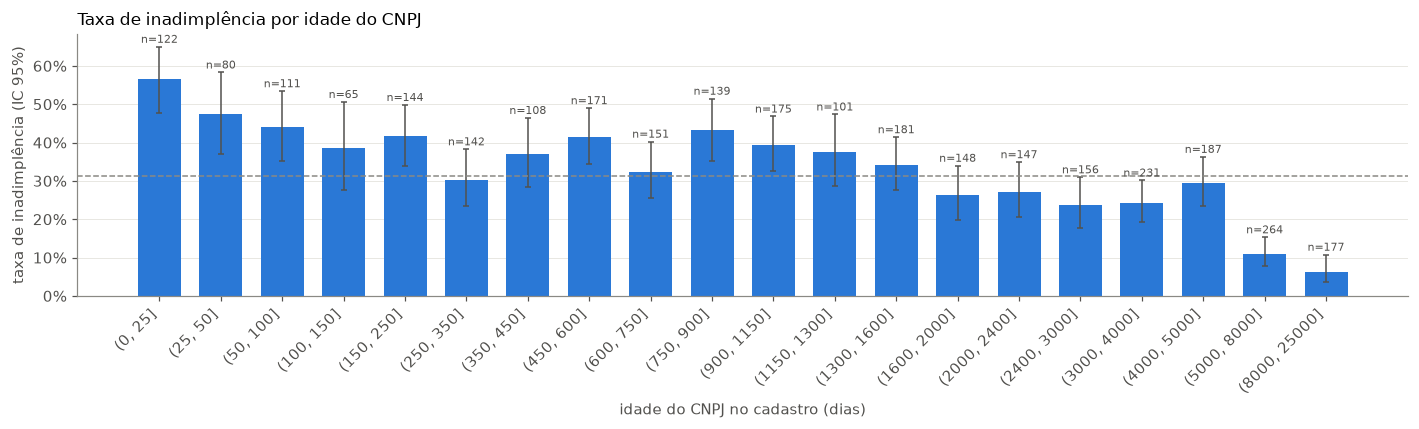

In [13]:
tab = taxa_por_grupo(clientes, "idade_cnpj")
plot_taxa(tab, "Taxa de inadimplência por idade do CNPJ", "eda_idade_cnpj.png", xlabel="idade do CNPJ no cadastro (dias)")

**Resposta:** **Sim, hipótese confirmada**, e é a variável com mais sinal (MI de 0,038, a maior da seção 5.3). A taxa cai de **57%** na faixa (0, 25] para **6%** na faixa (8.000, 25.000].

A queda não é linear:
- depois dos 57% da primeira faixa, a taxa oscila entre 30% e 48% até ~1.600 dias;
- entre 1.600 e 5.000 dias, fica perto de 25%;
- acima de **5.000 dias** (~14 anos), cai para 11% e depois 6%.

O degrau citado na descrição do problema (~2.400 dias) aparece aqui um pouco antes, por volta de 1.600 dias. O maior degrau vem depois, em 5.000.

### 4.2 Capital social

#### **Pergunta:** A inadimplência cai com o capital social?

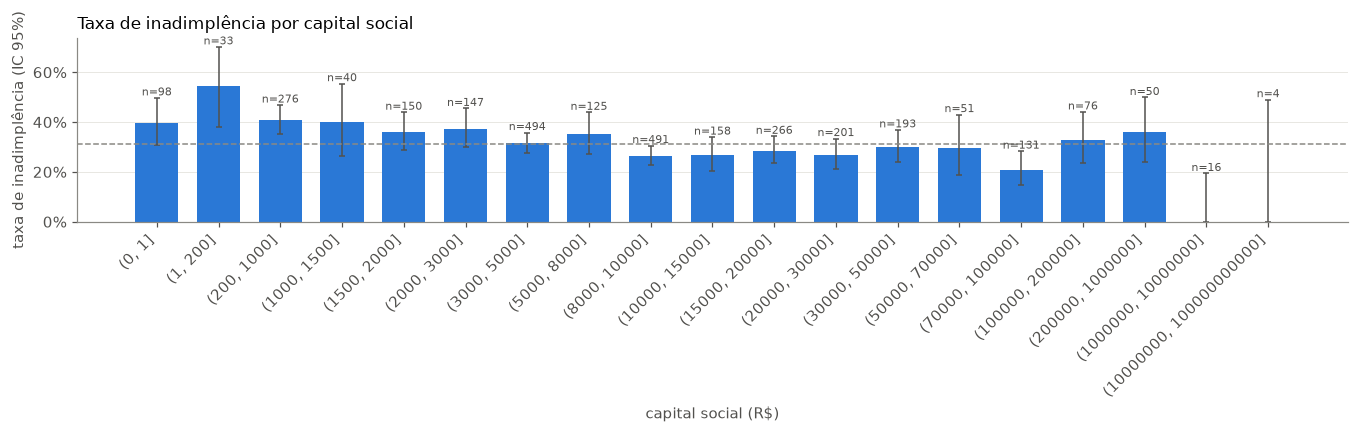

In [14]:
tab = taxa_por_grupo(clientes, "capital_social")
plot_taxa(tab, "Taxa de inadimplência por capital social", "eda_capital_social.png", xlabel="capital social (R$)")

**Resposta:** **Hipótese parcialmente confirmada.** A tendência existe, mas é fraca.

Em torno de 40% até R$ 1.500 e entre 21% e 30% de R$ 8.000 a R$ 100.000. A queda não é contínua: entre R$ 100.000 e R$ 1.000.000 a taxa volta a 33–36% (126 clientes). As duas faixas do topo não têm nenhum inadimplente, mas somam só 20 clientes. A MI (0,010) é baixa. Parte do sinal é compartilhada com LTDA (ρ = 0,55, seção 5.1).

### 4.3 Serasa

Negativações e protestos têm cauda longa, então foram agrupados em 0, 1, 2–5 e 6+.

#### **Pergunta:** Quem tem registro na Serasa inadimple mais? Importa a quantidade ou só ter algum registro?

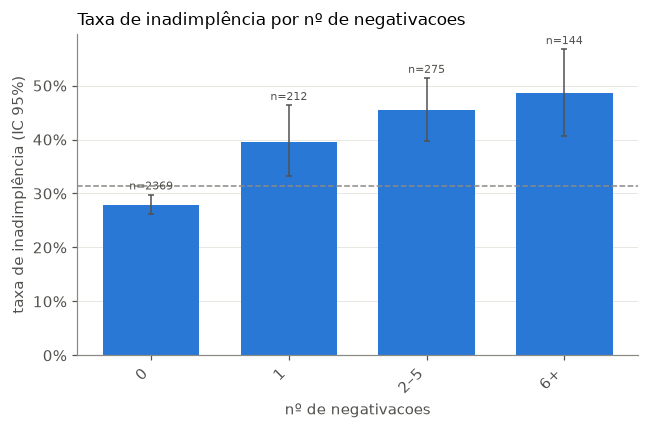

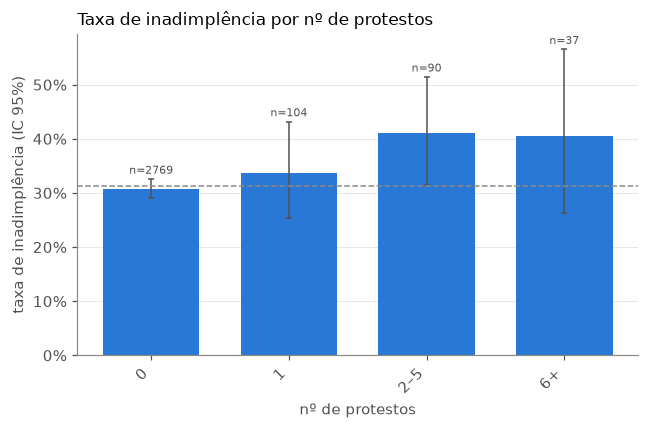

,n,inadimplentes,taxa,ic_inf,ic_sup
serasa_socio_tem_negativacao,,,,,
0,1573,348,0.221,0.201,0.242
1,1427,592,0.415,0.390,0.441


In [15]:
bins, rotulos = [-1, 0, 1, 5, np.inf], ["0", "1", "2–5", "6+"]
for col in ["serasa_contagem_negativacoes", "serasa_contagem_protestos"]:
    s = pd.cut(clientes[col], bins=bins, labels=rotulos)
    tab = taxa_por_grupo(clientes.assign(**{col: s}), col)
    nome = col.removeprefix("serasa_contagem_")
    plot_taxa(tab, f"Taxa de inadimplência por nº de {nome}", f"eda_{col}.png", xlabel=f"nº de {nome}")

taxa_por_grupo(clientes, "serasa_socio_tem_negativacao")

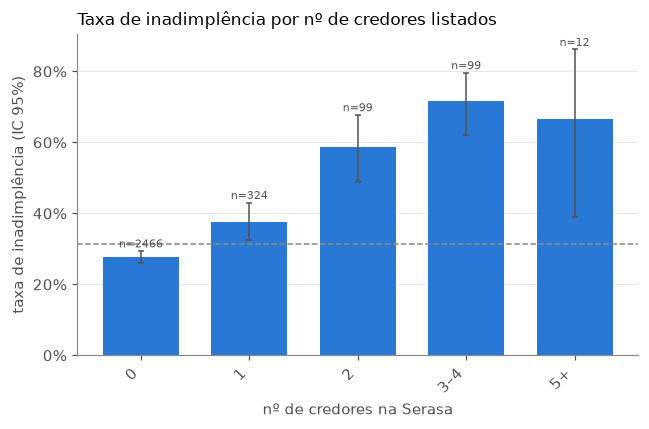

In [16]:
tab = taxa_por_grupo(clientes.assign(n_credores=pd.cut(aux["n_credores"], [-1, 0, 1, 2, 4, np.inf], labels=["0", "1", "2", "3–4", "5+"])), "n_credores")
plot_taxa(tab, "Taxa de inadimplência por nº de credores listados", "eda_n_credores.png", xlabel="nº de credores na Serasa")

**Resposta:** **Hipótese confirmada**.

Cada barra é a **taxa de inadimplência** observada no grupo, e o tracinho preto em cima dela é o **intervalo de confiança** de 95%, a faixa onde a taxa real do grupo deve estar.

O `n` é o número de clientes, e a linha tracejada é a taxa da base (31,3%). Quanto menor o grupo, maior o tracinho. No grupo sem credores (n = 2.466), a taxa é 27,6% e a faixa vai de 25,9% a 29,4%. No 5+ (n = 12), são 8 inadimplentes em 12 (66,7%), mas a faixa vai de 39% a 86%.

A queda do 3–4 para o 5+ não quer dizer nada: os tracinhos se sobrepõem e o 5+ tem poucos clientes para concluir algo. Quando os tracinhos de dois grupos não se sobrepõem, como no 0 e no 1, a diferença é real.

- **Negativações:** a taxa sobe de 27,9% (0) para 39,6% (1), 45,5% (2–5) e 48,6% (6+).

- **Número de credores:** é o gradiente mais forte, de 27,6% (nenhum) para 37,7% (1), 58,6% (2) e **71,7%** (3–4).

- **Sócio negativado:** **41,5%** contra 22,1%.

- **Protestos:** o sinal é fraco, de 30,8% para ~41% (MI de 0,001), porque só 7,7% dos clientes têm algum.

Portanto importa a quantidade, não só ter algum registro, principalmente no número de credores.

#### **Pergunta:** Dever a algum tipo de credor é pior que a outros?

`serasa_credores` é uma lista de até 5 segmentos de credores. Para cada segmento, a taxa de quem deve a pelo menos uma empresa dele. Segmentos com menos de 30 clientes ficam de fora.

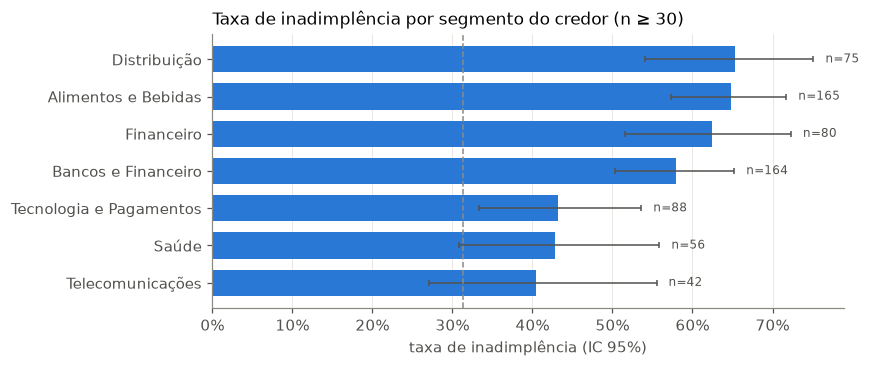

In [17]:
por_segmento = (
    clientes[["id_cliente", "inadimplente"]]
    .assign(segmento_credor=credores.map(lambda l: sorted({x.strip() for x in l}) if isinstance(l, list) else []))
    .explode("segmento_credor").dropna(subset=["segmento_credor"])
)
tab = taxa_por_grupo(por_segmento, "segmento_credor", ordenar_por_taxa=True)
plot_taxa(tab[tab["n"] >= 30], "Taxa de inadimplência por segmento do credor (n ≥ 30)", "eda_segmento_credor.png", horizontal=True)

**Resposta:** Todos os segmentos de credor com n ≥ 30 ficam acima da taxa da base, mas há dois níveis. O pior é dever a **Distribuição (65%)** e **Alimentos e Bebidas (65%)**, que são justamente fornecedores do mesmo tipo da Praso, seguidos de Financeiro (62%) e Bancos e Financeiro (58%), que são categorias separadas na base. Telecomunicações, Saúde e Tecnologia e Pagamentos ficam entre 40% e 43%.

Quem já deixou de pagar um fornecedor de mercadoria tende a repetir com a Praso.

### 4.4 Plataformas (iFood e Google Maps)

Nulo = não está na plataforma, e vira um grupo próprio.

#### **Pergunta:** Estar no iFood ou no Google Maps reduz a inadimplência? E o número de avaliações?

In [18]:
pd.concat(
    {col: taxa_por_grupo(clientes.assign(**{col: aux[col]}), col) for col in ["tem_ifood", "tem_google_maps", "tem_credores_serasa"]},
    names=["variável", "valor"],
)

n  inadimplentes  taxa  ic_inf  ic_sup
variável            valor                                           
tem_ifood           False  2637            843 0.320   0.302   0.338
                    True    363             97 0.267   0.224   0.315
tem_google_maps     False  2792            886 0.317   0.300   0.335
                    True    208             54 0.260   0.205   0.323
tem_credores_serasa False  2466            681 0.276   0.259   0.294
                    True    534            259 0.485   0.443   0.527

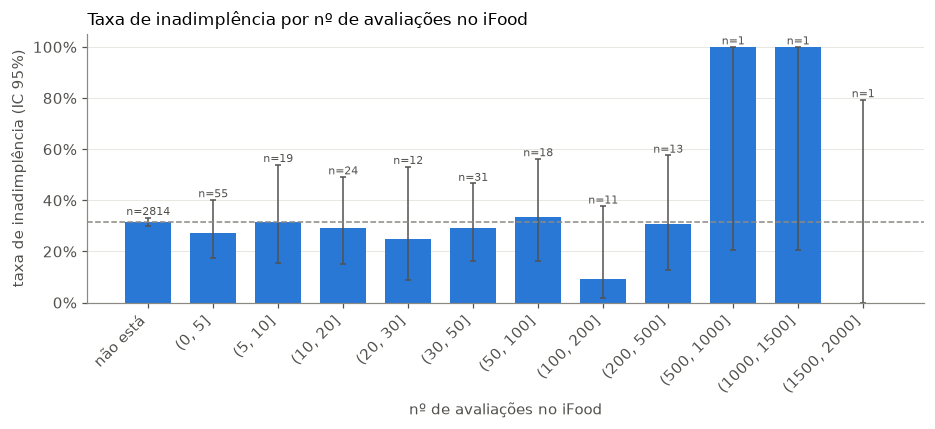

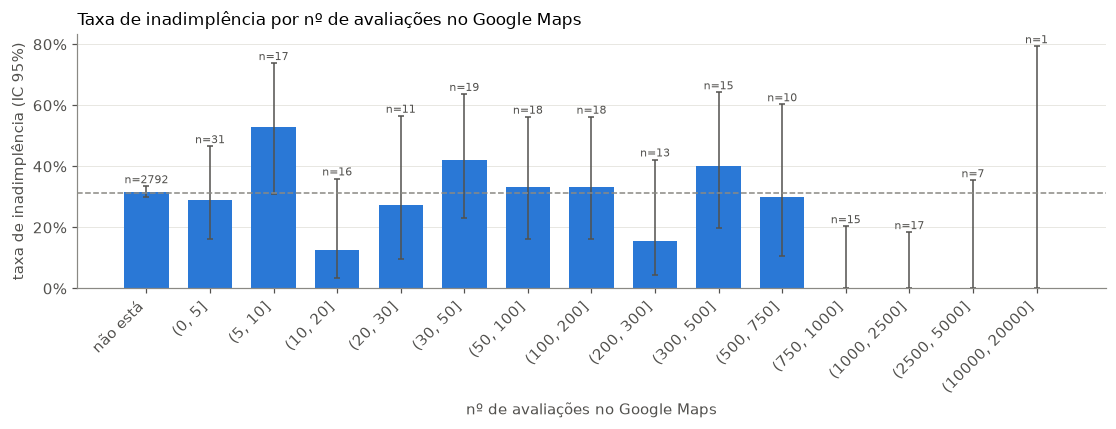

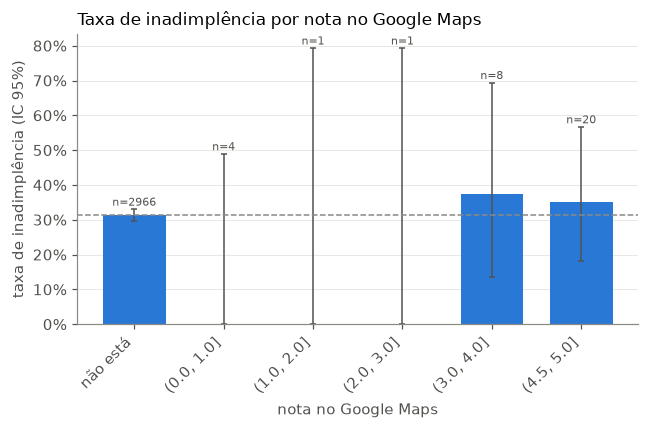

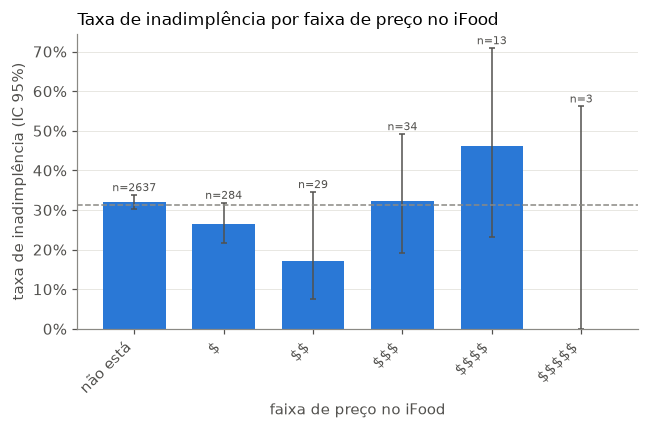

In [19]:
for col, titulo in [
    ("ifood_contagem_avaliacoes", "nº de avaliações no iFood"),
    ("google_maps_contagem_avaliacoes", "nº de avaliações no Google Maps"),
    ("google_maps_avaliacao", "nota no Google Maps"),
]:
    s = clientes[col].cat.add_categories("não está")
    s = s.cat.reorder_categories(["não está", *clientes[col].cat.categories]).fillna("não está")
    tab = taxa_por_grupo(clientes.assign(**{col: s}), col)
    plot_taxa(tab, f"Taxa de inadimplência por {titulo}", f"eda_{col}.png", xlabel=titulo)

ordem_preco = ["não está", "$", "$$", "$$$", "$$$$", "$$$$$"]
s = clientes["ifood_faixa_preco"].fillna("não está").astype(pd.CategoricalDtype(ordem_preco, ordered=True))
tab = taxa_por_grupo(clientes.assign(ifood_faixa_preco=s), "ifood_faixa_preco")
plot_taxa(tab, "Taxa de inadimplência por faixa de preço no iFood", "eda_ifood_faixa_preco.png", xlabel="faixa de preço no iFood")

**Resposta:** **Hipótese fraca.**

Estar no iFood (26,7% vs 32,0%) ou no Google Maps (26,0% vs 31,7%) reduz a taxa, mas os ICs quase se tocam e a MI é a menor de todas (0,001).

**O número de avaliações é parcial e vale só para o Google Maps.** Nenhum dos **40 clientes com mais de 750 avaliações** ficou inadimplente. Abaixo disso não há padrão claro. No iFood, nem a contagem nem a faixa de preço mostram tendência (grupos de 1 a 55 clientes). Como só 7% da base está no Google Maps, o efeito é forte mas atinge pouca gente.

### 4.5 Natureza jurídica e fonte

`uf` é constante (todos os clientes são do CE) e fica de fora.

#### **Pergunta:** Empresário individual inadimple mais que LTDA? A fonte de aquisição importa?

In [20]:
for col in ["natureza_juridica", "fonte_cliente"]:
    display(taxa_por_grupo(clientes, col, ordenar_por_taxa=True))

,n,inadimplentes,taxa,ic_inf,ic_sup
natureza_juridica,,,,,
224-0 - Sociedade Simples Limitada,2,0,0.000,0.000,0.658
230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária),12,1,0.083,0.015,0.354
206-2 - Sociedade Empresária Limitada,736,157,0.213,0.185,0.244
213-5 - Empresário (Individual),2249,781,0.347,0.328,0.367
205-4 - Sociedade Anônima Fechada,1,1,1.000,0.207,1.000


,n,inadimplentes,taxa,ic_inf,ic_sup
fonte_cliente,,,,,
Fonte 1,2055,560,0.273,0.254,0.292
Fonte 3,7,2,0.286,0.082,0.641
Fonte 5,736,276,0.375,0.341,0.411
Fonte 4,2,1,0.500,0.095,0.905
Fonte 2,200,101,0.505,0.436,0.574


**Resposta:** 

**Ambas as hipóteses estão confirmadas.** 
- Empresário individual tem **34,7%**, contra **21,3%** da LTDA. As outras três naturezas somam 15 clientes e não permitem conclusão.

- A Fonte 2 tem **50,5%** (n = 200) e a Fonte 5 tem 37,5% (n = 736), contra 27,3% da Fonte 1 (n = 2.055). As Fontes 3 e 4 têm 7 e 2 clientes.

A fonte é conhecida no cadastro, então pode entrar no modelo de aplicação. 

`(Pergunta: Praso mudou algum critério de fonte ao longo do tempo.)`

### 4.6 Segmento e CNAE

#### **Pergunta:** Há segmentos ou atividades (CNAE) bem mais arriscados?

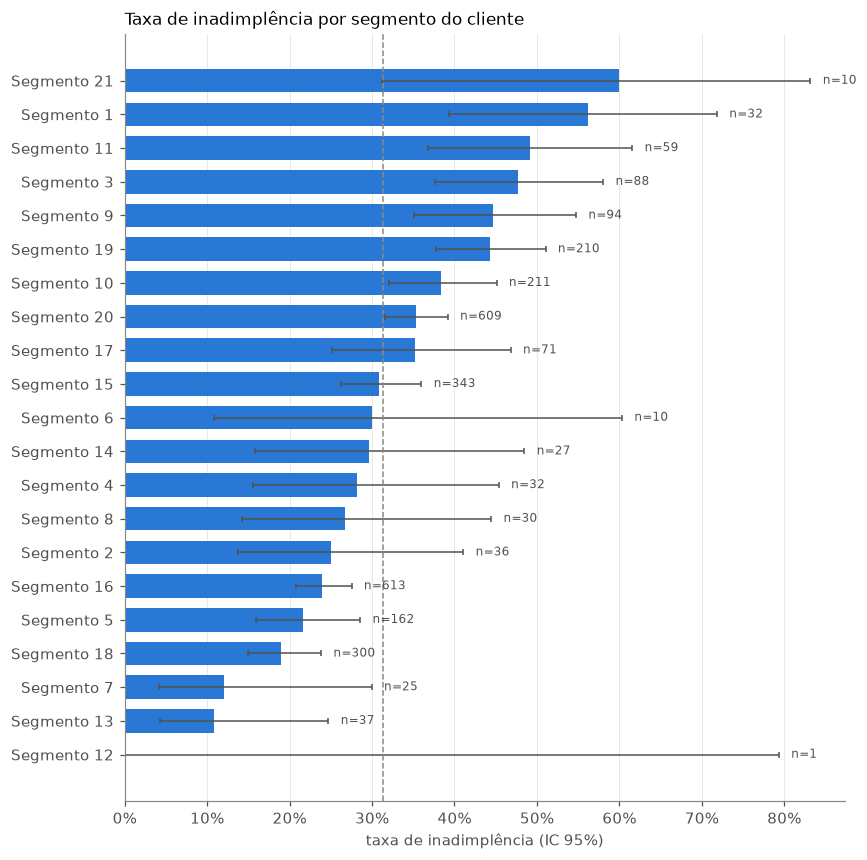

In [21]:
tab = taxa_por_grupo(clientes, "segmento_cliente", ordenar_por_taxa=True)
plot_taxa(tab, "Taxa de inadimplência por segmento do cliente", "eda_segmento_cliente.png", horizontal=True)

São 153 subclasses de CNAE, e 138 delas têm menos de 30 clientes. Olhamos os níveis acima dela: **divisão** (ex: `56`), **grupo** (ex: `56.1`) e **classe** (ex: `56.11-2`), juntando as categorias de menos de 30 clientes.

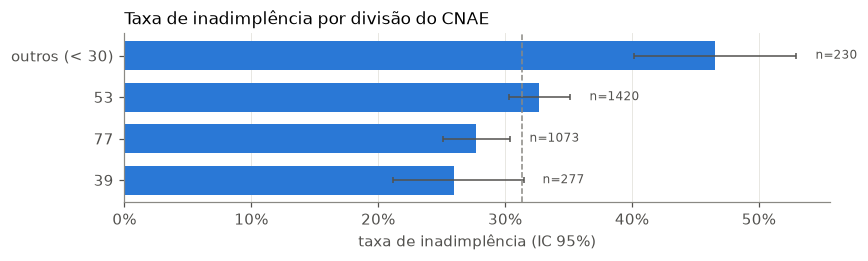

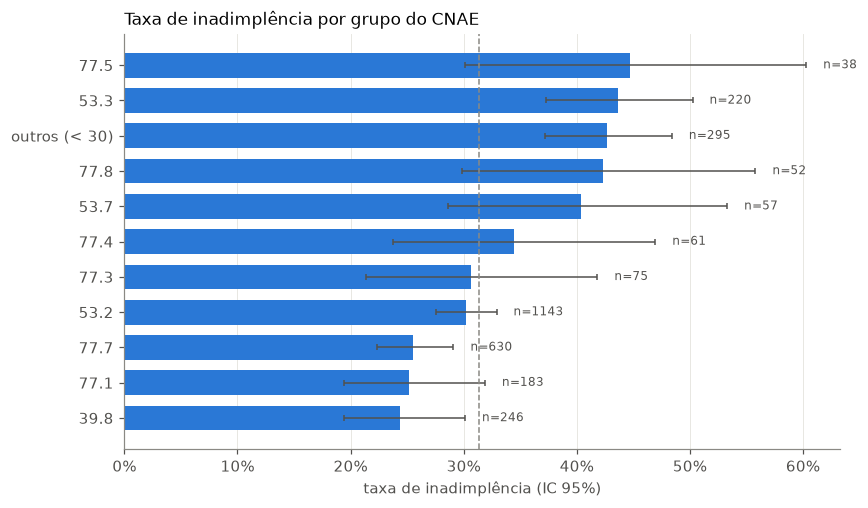

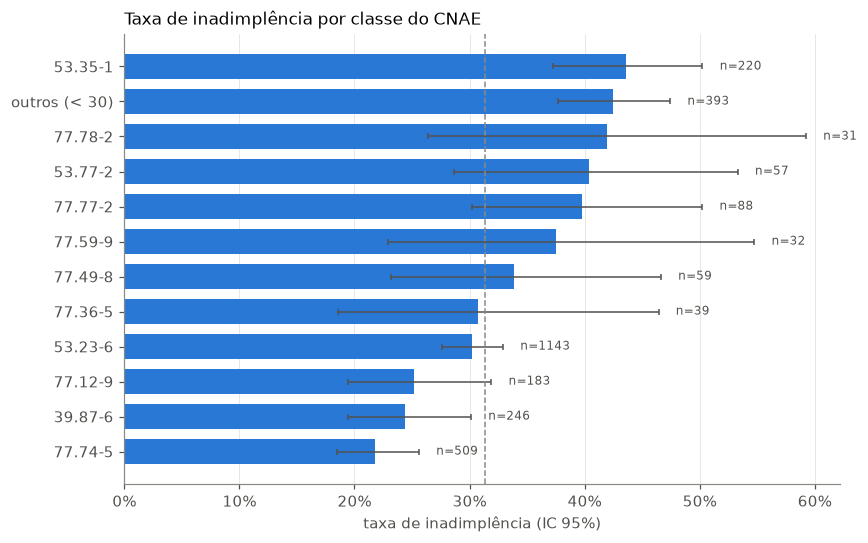

In [22]:
for nivel, col in [("divisão", "cnae_divisao"), ("grupo", "cnae_grupo"), ("classe", "cnae_classe")]:
    s = juntar_raros(aux[col])
    tab = taxa_por_grupo(clientes.assign(cnae=s), "cnae", ordenar_por_taxa=True)
    plot_taxa(tab, f"Taxa de inadimplência por {nivel} do CNAE", f"eda_cnae_{col.removeprefix('cnae_')}.png", horizontal=True)

**Resposta:** **Hipótese confirmada.** O tipo de negócio muda bastante o risco, e o segmento da Praso diz mais sobre isso do que o CNAE.

- **Segmento:** entre os 7 segmentos com mais de 100 clientes, em que a taxa é confiável, um cliente do Segmento 18 (n = 300) inadimple 19%, cerca de 40% abaixo da média da base, e um do Segmento 19 (n = 210) inadimple 44%, cerca de 40% acima. É mais que o dobro de risco só por mudar de segmento. Os extremos são segmentos pequenos, como o 13 (10,8%, n = 37) e o 1 (56,2%, n = 32), com ICs largos demais para concluir algo: o IC do Segmento 13 vai de 4% a 25% e cruza quase todo o do 18. Como os segmentos são anonimizados, não dá para dizer que tipo de negócio é mais arriscado, só que a diferença existe.

- **CNAE:** quase toda a base (92%) está em três divisões, e elas têm risco parecido (26% a 33%). Quem chama atenção é quem fica **fora** delas: os clientes de atividades pouco comuns na base inadimplem 46,5% (n = 230). Uma leitura possível é que são negócios mais distantes do perfil típico de cliente da Praso. Descer na hierarquia revela diferenças que os níveis de cima escondem: o grupo 77.7 parece um grupo médio (25,6%), mas mistura a classe 77.74-5, com 21,8% (n = 509), e a 77.77-2, com 39,8% (n = 88). Quanto mais fino o nível, mais sinal, desde que cada categoria tenha clientes suficientes.

- **Segmento × CNAE:** são variáveis diferentes. O CNAE é a atividade declarada no CNPJ, e o segmento é a classificação da própria Praso. Elas se parecem só em parte (V = 0,58 com a divisão), e o segmento se associa mais com a inadimplência (V = 0,19 contra 0,11–0,15 do CNAE). Uma explicação possível é que o segmento reflete o que o cliente realmente faz, enquanto o CNAE reflete o que foi declarado ao abrir a empresa.

Isso significa que o tipo de negócio deve entrar no modelo, e o segmento é a melhor forma de representá-lo. O CNAE pode complementar, de preferência no nível de classe e com as categorias raras agrupadas. Os segmentos e as classes pequenos precisam de agrupamento ou regularização, senão o modelo vai acreditar em taxas que saíram assim por acaso.


### 4.7 Município

#### **Pergunta:** Fortaleza e os outros municípios têm taxas diferentes?

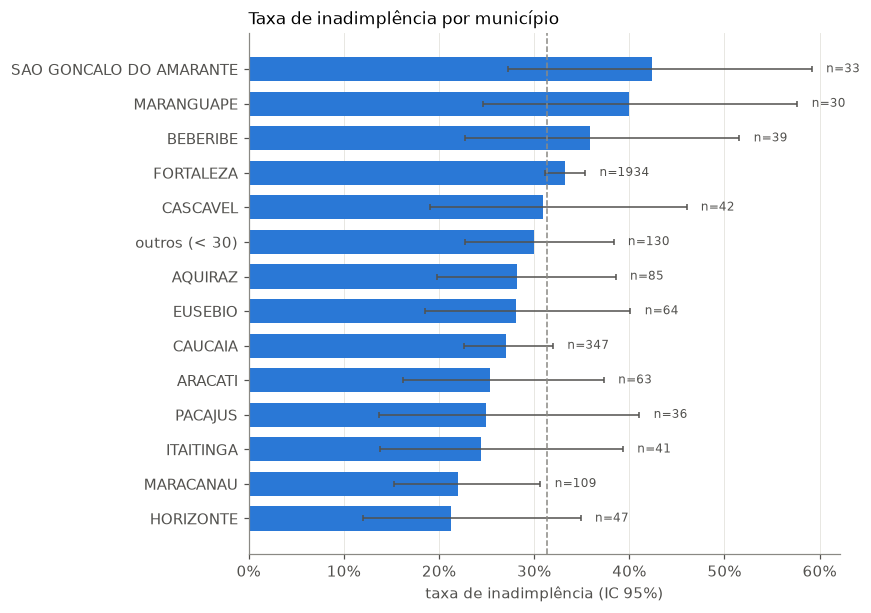

In [23]:
tab = taxa_por_grupo(clientes.assign(municipio=aux["municipio_agrup"]), "municipio", ordenar_por_taxa=True)
plot_taxa(tab, "Taxa de inadimplência por município", "eda_municipio.png", horizontal=True)

**Resposta:** **No nível de município, a hipótese não se confirma.**

Fortaleza tem 33,2%, e os outros municípios ficam entre 21% e 42%, com ICs largos que se sobrepõem. É a categórica mais fraca (V = 0,05 e MI = 0,003).

Pensando no modelo, no máximo uma flag de Fortaleza, ou deixar de fora.

#### **Pergunta:** Capital, região metropolitana e interior têm taxas diferentes?

Como o enunciado sugere, os municípios foram agrupados em três regiões: Fortaleza, os outros 18 municípios da [Região Metropolitana de Fortaleza](https://www.ipece.ce.gov.br/wp-content/uploads/sites/45/2021/03/PANORAMA_SOCIOECONOMICO_DAS_REGIOES_METROPOLITANAS_CEARENSES_2018.pdf) e o interior.

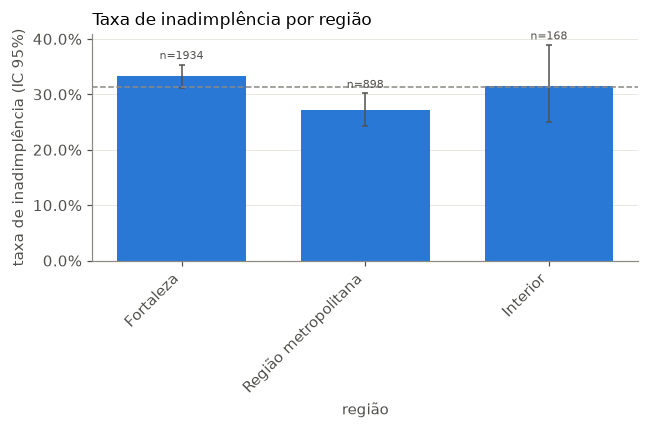

,n,inadimplentes,taxa,ic_inf,ic_sup,municípios na base
regiao,,,,,,
Fortaleza,1934,643,0.332,0.312,0.354,1
Região metropolitana,898,244,0.272,0.244,0.302,16
Interior,168,53,0.315,0.250,0.389,19


In [24]:
# Região Metropolitana de Fortaleza: Fortaleza + 18 municípios (IPECE)
RMF = {
    "AQUIRAZ", "CASCAVEL", "CAUCAIA", "CHOROZINHO", "EUSEBIO", "GUAIUBA", "HORIZONTE", "ITAITINGA", "MARACANAU",
    "MARANGUAPE", "PACAJUS", "PACATUBA", "PARACURU", "PARAIPABA", "PINDORETAMA", "SAO GONCALO DO AMARANTE",
    "SAO LUIS DO CURU", "TRAIRI",
}
regiao = clientes["municipio"].map(lambda m: "Fortaleza" if m == "FORTALEZA" else "Região metropolitana" if m in RMF else "Interior")
regiao = regiao.astype(pd.CategoricalDtype(["Fortaleza", "Região metropolitana", "Interior"], ordered=True))

tab = taxa_por_grupo(clientes.assign(regiao=regiao), "regiao")
tab["municípios na base"] = clientes.groupby(regiao, observed=True)["municipio"].nunique()
plot_taxa(tab, "Taxa de inadimplência por região", "eda_regiao.png", xlabel="região")
tab

**Resposta:** **Hipótese parcialmente confirmada.** Agrupando por região aparece uma diferença que o município a município escondia.

- **Fortaleza (33,2%, n = 1.934) inadimple mais que a região metropolitana (27,2%, n = 898).** São 6 pontos de diferença, e os ICs não se cruzam (31,2% a 35,4% contra 24,4% a 30,2%).
- **O interior (31,5%, n = 168) não dá para comparar:** tem poucos clientes, e o IC vai de 25% a 39%.
- **O sinal continua fraco para ordenar clientes.** O ROC-AUC da região sozinha é 0,518 (seção 5.4), quase o mesmo que sortear. A diferença existe na média, mas separa pouco os clientes individualmente.

A hipótese original era capital × interior, e o que aparece é capital × região metropolitana. Uma leitura possível é que o varejo da capital é mais concorrido e tem margens menores, mas os dados não permitem confirmar. Para o modelo, uma flag de Fortaleza ou a região em 3 níveis são candidatas de prioridade baixa.


### 4.8 Histórico de pedidos

O enunciado pede para comparar também `valor` e `atraso` com a inadimplência. Esta seção olha o histórico dos 664 clientes com pedidos, com poucos agregados simples, só para entender os dados. A escolha das features do modelo comportamental fica para a etapa de agregações.

Cuidado: como a base não tem data de referência (seção 7), não dá para saber se esses pedidos são anteriores ao momento em que a inadimplência foi observada.

#### **Pergunta:** Quantos pedidos cada cliente tem na base?

In [25]:
n_por_cliente = pedidos.groupby("id_cliente").size().rename("n_pedidos")
hist = clientes.set_index("id_cliente").loc[n_por_cliente.index, ["inadimplente"]].join(n_por_cliente)
taxa_por_grupo(hist, "n_pedidos")

,n,inadimplentes,taxa,ic_inf,ic_sup
n_pedidos,,,,,
1,2,2,1.000,0.342,1.000
2,11,9,0.818,0.523,0.949
3,651,127,0.195,0.166,0.227


**Resposta:** **Nenhum cliente tem mais de 3 pedidos na base.** 651 dos 664 clientes têm exatamente 3, 11 têm 2 e 2 têm 1.

Isso indica que a Praso entregou só **até 3 pedidos por cliente**, provavelmente uma amostra ou um recorte do histórico real (pergunta em aberto 7). Duas consequências:

- **Contagens viram pouco informativas.** Features como "quantos pedidos ele já fez", sugerida no enunciado, não fazem sentido com esse corte. O que dá para medir são proporções e o pior caso dentro dos 3 pedidos.
- **Ter menos de 3 pedidos é um sinal de alerta de vazamento.** 11 dos 13 clientes com menos de 3 pedidos são inadimplentes (85%), contra 19,5% de quem tem 3. Uma explicação plausível é que quem inadimple para de comprar, ou é bloqueado. Se for isso, o número de pedidos já carrega o resultado, e usá-lo como feature seria usar o alvo para prever o alvo.


#### **Pergunta:** Quem atrasa mais inadimple mais? E o valor dos pedidos importa?

Para cada cliente: quantos dos seus pedidos tiveram atraso, o pior atraso entre eles (a faixa mais alta) e o valor médio, usando o ponto médio das faixas de valor. A tabela no fim mostra o ROC-AUC de cada agregado sozinho (seção 5.4) e o da idade do CNPJ nos mesmos 664 clientes, para comparar.

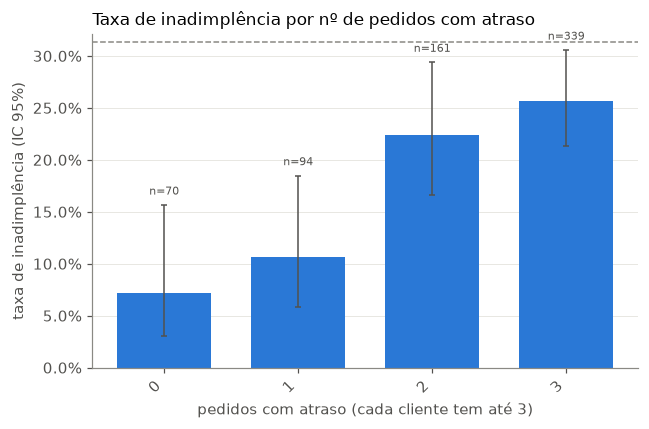

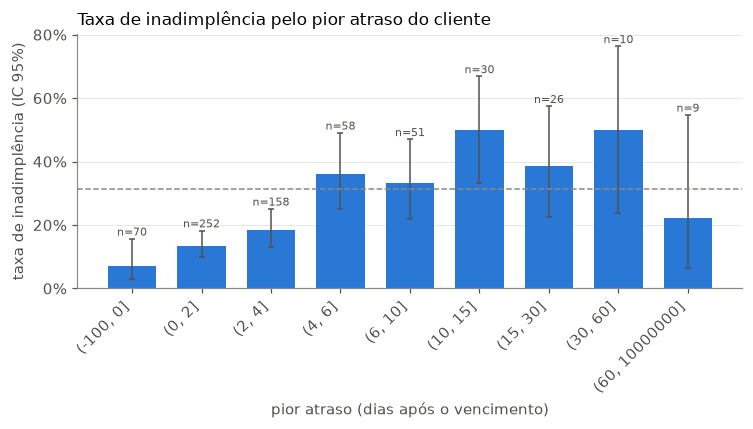

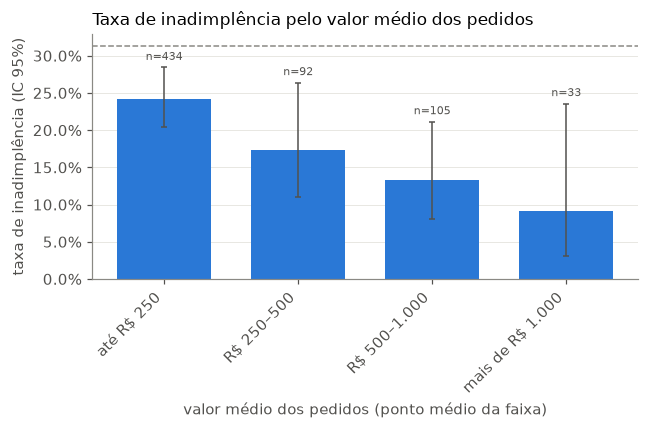

,ROC-AUC nos 664 clientes com pedidos
pior atraso,0.677
nº de pedidos com atraso,0.601
valor médio (maior valor = menor risco),0.576
"idade do CNPJ, para comparar (mais velho = menor risco)",0.647


In [26]:
cod_atraso = pedidos["atraso"].cat.codes.where(pedidos["atraso"].notna())  # código 0 = "(-100, 0]", sem atraso
por_pedido = pedidos.assign(
    cod_atraso=cod_atraso,
    atrasou=(cod_atraso > 0).where(cod_atraso.notna()),
    valor_pm=ponto_medio(pedidos["valor"]),
)
agregados = por_pedido.groupby("id_cliente").agg(
    pedidos_com_atraso=("atrasou", "sum"),
    pior_atraso=("cod_atraso", "max"),
    valor_medio=("valor_pm", "mean"),
)
hist = hist.join(agregados)
hist["pedidos_com_atraso"] = hist["pedidos_com_atraso"].astype(int)
hist["pior_atraso"] = pd.Categorical.from_codes(
    hist["pior_atraso"].fillna(-1).astype(int), categories=pedidos["atraso"].cat.categories, ordered=True)
hist["valor_medio_faixa"] = pd.cut(hist["valor_medio"], [0, 250, 500, 1000, np.inf],
                                   labels=["até R$ 250", "R$ 250–500", "R$ 500–1.000", "mais de R$ 1.000"])

plot_taxa(taxa_por_grupo(hist, "pedidos_com_atraso"), "Taxa de inadimplência por nº de pedidos com atraso",
          "eda_hist_pedidos_com_atraso.png", xlabel="pedidos com atraso (cada cliente tem até 3)")
plot_taxa(taxa_por_grupo(hist, "pior_atraso"), "Taxa de inadimplência pelo pior atraso do cliente",
          "eda_hist_pior_atraso.png", xlabel="pior atraso (dias após o vencimento)")
plot_taxa(taxa_por_grupo(hist, "valor_medio_faixa"), "Taxa de inadimplência pelo valor médio dos pedidos",
          "eda_hist_valor_medio.png", xlabel="valor médio dos pedidos (ponto médio da faixa)")

idade_codigo = clientes.set_index("id_cliente").loc[hist.index, "idade_cnpj"].cat.codes
pd.Series({
    "pior atraso": roc_auc_score(hist["inadimplente"], hist["pior_atraso"].cat.codes),
    "nº de pedidos com atraso": roc_auc_score(hist["inadimplente"], hist["pedidos_com_atraso"]),
    "valor médio (maior valor = menor risco)": roc_auc_score(hist["inadimplente"], -hist["valor_medio"]),
    "idade do CNPJ, para comparar (mais velho = menor risco)": roc_auc_score(hist["inadimplente"], -idade_codigo),
}, name="ROC-AUC nos 664 clientes com pedidos").to_frame()

**Resposta:** **Hipótese confirmada: o atraso é o sinal mais forte do histórico, e mais forte até que a idade do CNPJ nesses clientes.**

- **Pior atraso:** quem nunca atrasou inadimple 7,1% (n = 70). Com atraso de 1 a 2 dias, 13,5%; de 3 a 4 dias, 18,4%. A partir de 5 dias, a taxa sobe para 33% a 50%, acima da média da base. Os grupos acima de 15 dias têm poucos clientes e ICs largos, e o de mais de 60 dias (22%, n = 9) não permite concluir nada.
- **Número de pedidos com atraso:** a taxa sobe de 7,1% (nenhum) para 10,6% (1), 22,4% (2) e 25,7% (os 3). A maioria dos clientes atrasa pelo menos um pouco: só 70 dos 664 nunca atrasaram.
- **Valor médio:** quem faz pedidos maiores inadimple menos, de 24,2% (até R$ 250, n = 434) para 9,1% (mais de R$ 1.000, n = 33). Uma leitura possível é que pedidos maiores indicam um negócio com mais giro. Isso importa para a política de crédito: os clientes de maior risco tendem a ser os de menor valor exposto.
- **Comparação pelo ROC-AUC, nos mesmos 664 clientes:** o pior atraso sozinho tem 0,677, acima da idade do CNPJ (0,647), que é a melhor variável de cadastro. O número de pedidos com atraso tem 0,601 e o valor médio, 0,576.

**O que isso significa:** o histórico de pagamento acrescenta informação real ao modelo comportamental, e o pior atraso é o candidato mais forte. Mas vale o cuidado do 4.8: sem data de referência, parte desse sinal pode vir de pedidos posteriores ao momento em que a inadimplência foi observada.


## 5. Correlação e redundância

Continuação da **análise bivariada**, mas entre pares de variáveis que não são o target.

O objetivo é achar as que medem a mesma coisa e ver, lado a lado, quanto cada uma informa sobre o alvo.

### 5.1 Variáveis ordenáveis (Spearman)

Por conta do tipo das variáveis, optou-se por utilizar a correlação de Spearman, e não a de Pearson. 

As faixas (idade do CNPJ, capital social, avaliações) não são números, só têm ordem. As contagens da Serasa têm cauda longa, e Pearson seria puxado pelos poucos clientes com valores muito altos. Spearman olha só a ordem dos valores (quem é maior que quem), então funciona nos dois casos.

Cada faixa entra pela sua posição na ordem: 0 para a menor, 1 para a seguinte, e assim por diante. As variáveis do iFood e do Google Maps só existem para quem está na plataforma, então cada correlação usa apenas os clientes que têm as duas variáveis do par preenchidas.

#### **Pergunta:** Quais variáveis medem praticamente a mesma coisa (|ρ| > 0,85)?

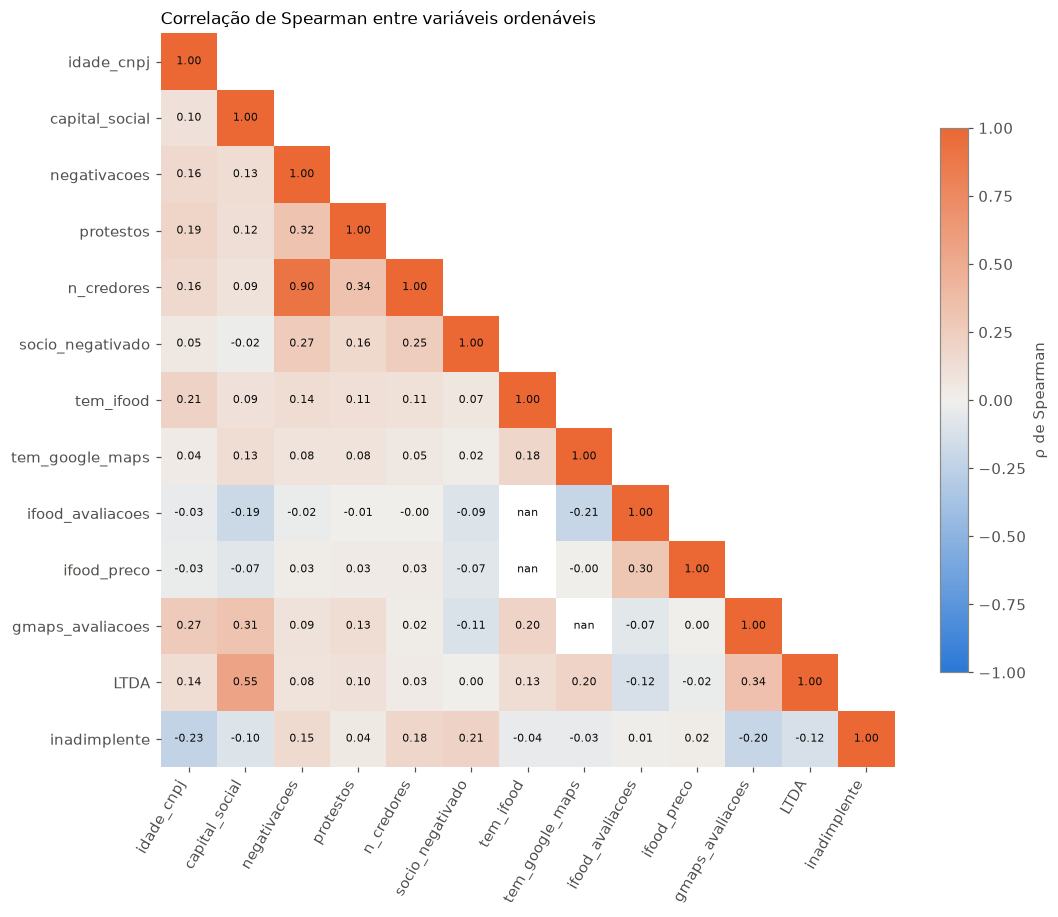

,,ρ
n_credores,negativacoes,0.900
LTDA,capital_social,0.551


In [27]:
ordenaveis = pd.DataFrame({
    "idade_cnpj": clientes["idade_cnpj"].cat.codes,
    "capital_social": clientes["capital_social"].cat.codes,
    "negativacoes": clientes["serasa_contagem_negativacoes"],
    "protestos": clientes["serasa_contagem_protestos"],
    "n_credores": aux["n_credores"],
    "socio_negativado": clientes["serasa_socio_tem_negativacao"],
    "tem_ifood": aux["tem_ifood"].astype(int),
    "tem_google_maps": aux["tem_google_maps"].astype(int),
    "ifood_avaliacoes": clientes["ifood_contagem_avaliacoes"].cat.codes.replace(-1, np.nan),
    "ifood_preco": clientes["ifood_faixa_preco"].str.len(),
    "gmaps_avaliacoes": clientes["google_maps_contagem_avaliacoes"].cat.codes.replace(-1, np.nan),
    "LTDA": clientes["natureza_juridica"].str.startswith("206-2").astype(int),
    "inadimplente": clientes["inadimplente"],
})
corr = ordenaveis.corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.mask(mascara), cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
ax.grid(False)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlação de Spearman entre variáveis ordenáveis", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_spearman.png", dpi=150); plt.show()

pares = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
pares[pares.abs() >= 0.5].sort_values(key=abs, ascending=False).rename("ρ").to_frame()

**Resposta:**

Só um par passa de 0,85: **número de credores × negativações (ρ = 0,90)**. As duas medem quase a mesma coisa, então em uma regressão logística vale manter só uma, de preferência o número de credores, que tem mais sinal.

O par seguinte é LTDA × capital social (0,55): relacionadas, mas não redundantes.

Com o alvo, as maiores correlações são da idade do CNPJ (−0,23), do sócio negativado (+0,21), das avaliações no Google Maps (−0,20, só entre quem está no Maps) e do número de credores (+0,18).

Os `nan` são pares que nunca coexistem, por exemplo as avaliações no iFood de quem não está no iFood.

### 5.2 Categóricas (V de Cramér)

Correlação não se aplica a categóricas nominais. O V de Cramér mede o quanto uma determina a outra (0 a 1). Categorias com menos de 30 clientes foram juntadas, para a medida não inflar com grupos minúsculos.

#### **Pergunta:** Segmento, CNAE e natureza jurídica trazem informação diferente ou são redundantes?

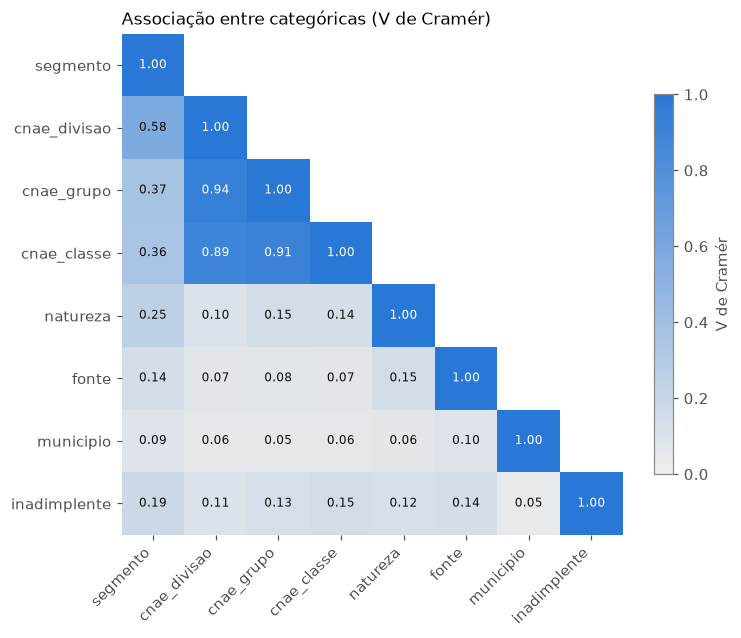

In [28]:
nominais = {
    "segmento": clientes["segmento_cliente"],
    "cnae_divisao": juntar_raros(aux["cnae_divisao"]),
    "cnae_grupo": aux["cnae_grupo_agrup"],
    "cnae_classe": aux["cnae_classe_agrup"],
    "natureza": juntar_raros(clientes["natureza_juridica"]),
    "fonte": juntar_raros(clientes["fonte_cliente"]),
    "municipio": aux["municipio_agrup"],
    "inadimplente": clientes["inadimplente"],
}
nomes = list(nominais)
cv = pd.DataFrame([[cramers_v(nominais[a], nominais[b]) for b in nomes] for a in nomes], index=nomes, columns=nomes)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cv.mask(np.triu(np.ones_like(cv, dtype=bool), k=1)), cmap=CMAP_SEQUENCIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(cv)), cv.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cv)), cv.index)
for i in range(len(cv)):
    for j in range(i + 1):
        ax.text(j, i, f"{cv.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cv.iat[i, j] > 0.6 else "#0b0b0b")
ax.grid(False)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="V de Cramér")
ax.set_title("Associação entre categóricas (V de Cramér)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_cramers_v.png", dpi=150); plt.show()

**Resposta:** Só o CNAE é redundante consigo mesmo. As demais variáveis categóricas trazem, cada uma, informação própria.

- **Divisão, grupo e classe do CNAE (V de 0,89 a 0,94 entre si):** são praticamente a mesma variável em resoluções diferentes. Sabendo a classe (`77.74-5`), você já sabe o grupo (`77.7`) e a divisão (`77`). O V só não chega a 1 porque as categorias raras foram juntadas em "outros" (o "outros" do grupo mistura várias divisões) e por causa da correção de viés. Colocar os três níveis no modelo seria contar a mesma informação três vezes, então é preciso escolher um. A classe é a que mais se associa com a inadimplência (V = 0,15, contra 0,13 do grupo e 0,11 da divisão), como já tinha aparecido no 4.6.

- **Segmento × CNAE:** associação moderada (0,58 com a divisão, 0,37 com o grupo e 0,36 com a classe). Saber o segmento dá uma boa pista da divisão do CNAE, mas não a determina. Clientes do mesmo segmento da Praso aparecem em CNAEs diferentes, e vice-versa. Ou seja, o segmento não é só um recorte do CNAE, e as duas variáveis podem entrar juntas no modelo.

- **Natureza jurídica, fonte e município:** quase não se relacionam entre si (V de 0,06 a 0,15). A maior associação delas é da natureza jurídica com o segmento (0,25), o que faz sentido se alguns segmentos tiverem mais LTDAs e outros mais empresários individuais. Cada uma mede uma coisa diferente.

- **Com o alvo:** nenhuma categórica tem associação forte com a inadimplência. A ordem é segmento (0,19), classe do CNAE (0,15), fonte (0,14), grupo do CNAE (0,13), natureza (0,12), divisão do CNAE (0,11) e município (0,05). Isso confirma o 4.7: o município é a variável que menos informa.


### 5.3 O que mais informa sobre o alvo (informação mútua)

A informação mútua (MI) responde a uma pergunta simples: **saber o valor desta variável ajuda a adivinhar se o cliente vai inadimplir?** Se não ajuda nada, a MI é 0. Quanto mais ajuda, maior ela fica.

Ela complementa o Spearman e o V de Cramér por dois motivos:
- **Coloca todas as variáveis na mesma régua.** O Spearman só vale para variáveis com ordem, e o V só para categóricas. Com a MI, dá para comparar idade do CNPJ, segmento e sócio negativado lado a lado, num único ranking.

- **Pega relações que não são "sobe junto".** Se o risco fosse alto nas empresas muito novas **e** nas muito antigas, e baixo no meio, o Spearman daria perto de 0, mas a MI captaria o padrão.

Como as variáveis entram no cálculo:
- Toda variável é tratada como um conjunto de categorias. Cada faixa é uma categoria, e "não está na plataforma" (nulo) também.

- Negativações e protestos entram nas faixas do 4.3 (0, 1, 2–5, 6+), o número de credores vai de 0 a 5+, e as categóricas entram com os raros juntados em "outros". Isso é necessário porque, quanto mais categorias uma variável tem, maior a MI sai só por acaso: uma variável com 153 categorias quase vazias pareceria informativa sem ser.

> Este ranking serve para entender os dados e usa a base inteira. **Não deve ser usado para escolher as features do modelo:** se a escolha usasse a base inteira, os dados de teste influenciariam a seleção e o desempenho medido sairia otimista.

#### **Pergunta:** Quais variáveis carregam mais informação sobre a inadimplência?

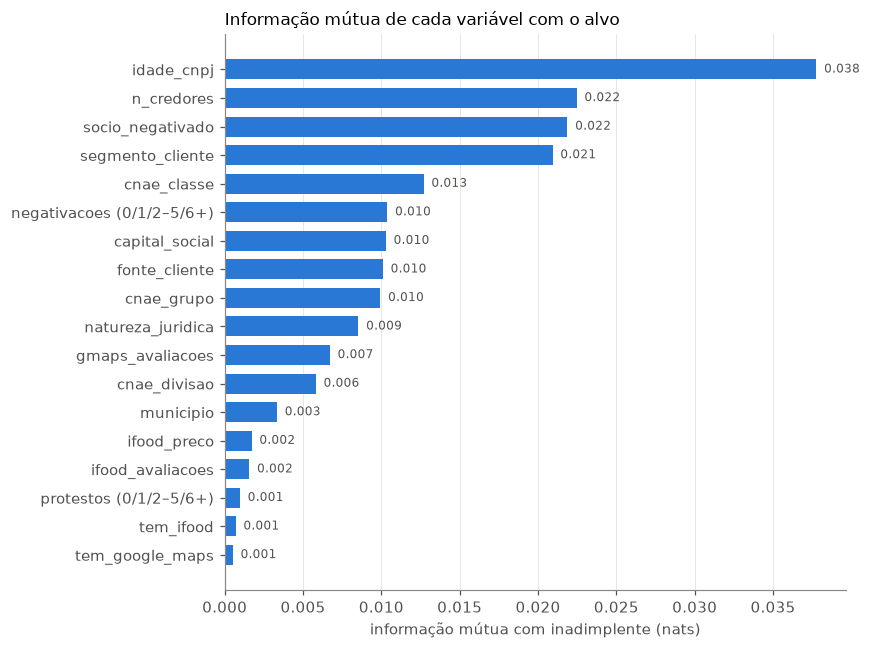

In [29]:
candidatas = pd.DataFrame({
    "idade_cnpj": clientes["idade_cnpj"].cat.codes,
    "capital_social": clientes["capital_social"].cat.codes,
    "negativacoes (0/1/2–5/6+)": pd.cut(clientes["serasa_contagem_negativacoes"], bins, labels=False),
    "protestos (0/1/2–5/6+)": pd.cut(clientes["serasa_contagem_protestos"], bins, labels=False),
    "n_credores": aux["n_credores"].clip(upper=5),
    "socio_negativado": clientes["serasa_socio_tem_negativacao"],
    "tem_ifood": aux["tem_ifood"].astype(int),
    "tem_google_maps": aux["tem_google_maps"].astype(int),
    "ifood_avaliacoes": clientes["ifood_contagem_avaliacoes"].cat.codes,
    "ifood_preco": clientes["ifood_faixa_preco"].str.len().fillna(0),
    "gmaps_avaliacoes": clientes["google_maps_contagem_avaliacoes"].cat.codes,
    "natureza_juridica": pd.factorize(juntar_raros(clientes["natureza_juridica"]))[0],
    "fonte_cliente": pd.factorize(juntar_raros(clientes["fonte_cliente"]))[0],
    "segmento_cliente": pd.factorize(clientes["segmento_cliente"])[0],
    "cnae_divisao": pd.factorize(juntar_raros(aux["cnae_divisao"]))[0],
    "cnae_grupo": pd.factorize(aux["cnae_grupo_agrup"])[0],
    "cnae_classe": pd.factorize(aux["cnae_classe_agrup"])[0],
    "municipio": pd.factorize(aux["municipio_agrup"])[0],
})
mi = pd.Series(
    mutual_info_classif(candidatas, clientes["inadimplente"], discrete_features=True, random_state=42),
    index=candidatas.columns,
).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(mi)), mi.values, color=AZUL, height=0.7)
ax.set_yticks(range(len(mi)), mi.index)
ax.set_xlabel("informação mútua com inadimplente (nats)")
ax.grid(axis="y", visible=False)
for y, val in enumerate(mi.values):
    ax.text(val + 0.0005, y, f"{val:.3f}", va="center", fontsize=8, color=TEXTO)
ax.set_title("Informação mútua de cada variável com o alvo", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_informacao_mutua.png", dpi=150); plt.show()

**Resposta:**

Em ordem: **idade do CNPJ** (0,038) bem à frente, depois **número de credores**, **sócio negativado** e **segmento** (~0,022 cada) e a classe do CNAE (0,013).

Capital social, negativações, fonte, natureza e o grupo do CNAE ficam perto de 0,010, e a divisão do CNAE fica em 0,006. A presença no iFood e no Google Maps, os protestos e as variáveis do iFood quase não informam (≤ 0,002).

Os valores são baixos em termos absolutos (o máximo para um alvo binário com 31% é ~0,62 nats). Nenhuma variável sozinha resolve: o modelo vai depender da combinação.

### 5.4 Quanto cada variável ordena sozinha (ROC-AUC)

O modelo da Praso é avaliado por ROC-AUC, porque o que importa é **ordenar** os clientes: um inadimplente deve ter score maior que um adimplente. Aqui medimos o AUC de cada variável sozinha, usando como score a taxa de inadimplência da categoria do cliente. Um AUC de 0,5 é o mesmo que sortear, e 1 é ordenar perfeitamente.

Para a medida não sair otimista, a taxa de cada categoria é calculada em 4/5 da base e aplicada no 1/5 restante, em 5 rodadas (validação cruzada). Assim, nenhum cliente é avaliado com uma taxa que usou o próprio resultado. As variáveis entram como na seção 5.3, mais a região do 4.7.

> Como a MI, este ranking serve para entender os dados e usa a base inteira. **Não deve ser usado para escolher as features do modelo.**

#### **Pergunta:** Qual é o ROC-AUC de cada variável sozinha?

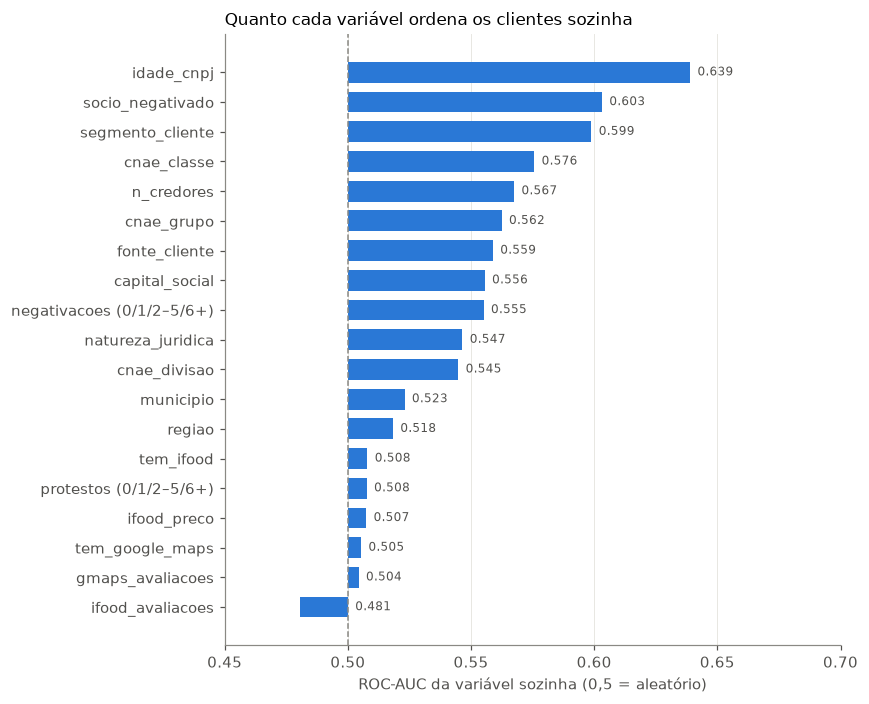

In [30]:
y = clientes["inadimplente"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def auc_fora_da_amostra(x: pd.Series) -> float:
    """ROC-AUC de usar a taxa de inadimplência de cada categoria como score, com a taxa vinda de outros folds."""
    x = x.astype(str)
    score = pd.Series(np.nan, index=x.index)
    for treino, teste in folds.split(x, y):
        taxa = y.iloc[treino].groupby(x.iloc[treino]).mean()
        score.iloc[teste] = x.iloc[teste].map(taxa).fillna(y.iloc[treino].mean()).to_numpy()
    return roc_auc_score(y, score)


auc = pd.Series({col: auc_fora_da_amostra(x) for col, x in candidatas.assign(regiao=regiao.astype(str)).items()}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(range(len(auc)), auc.values - 0.5, left=0.5, color=AZUL, height=0.7)
ax.axvline(0.5, color=CINZA, ls="--", lw=1)
ax.set_yticks(range(len(auc)), auc.index)
ax.set_xlim(0.45, 0.7)
ax.set_xlabel("ROC-AUC da variável sozinha (0,5 = aleatório)")
ax.grid(axis="y", visible=False)
for yi, val in enumerate(auc.values):
    ax.text(max(val, 0.5) + 0.003, yi, f"{val:.3f}", va="center", fontsize=8, color=TEXTO)
ax.set_title("Quanto cada variável ordena os clientes sozinha", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_auc_univariada.png", dpi=150); plt.show()

**Resposta:** **Nenhuma variável ordena bem sozinha: a melhor, a idade do CNPJ, tem ROC-AUC de 0,639.** A ordem é parecida com a da informação mútua (5.3), agora na métrica do desafio. A diferença é o número de credores, que cai do 2º lugar na MI para o 5º aqui.

- **As que mais ordenam:** idade do CNPJ (0,639), sócio negativado (0,603) e segmento (0,599), seguidas da classe do CNAE (0,576) e do número de credores (0,567).
- **Intermediárias (0,54 a 0,56):** grupo do CNAE, fonte, capital social, negativações, natureza jurídica e divisão do CNAE.
- **Quase iguais a sortear (≤ 0,52):** município, região, presença no iFood e no Google Maps, protestos e as variáveis de avaliação. As avaliações do iFood ficam até abaixo de 0,5 (0,481), o que é ruído: com poucos clientes por faixa, a taxa de um fold não se repete no outro.

**O que isso significa:** os modelos de aplicação devem superar com folga 0,64, o AUC de usar só a idade do CNPJ, que serve de linha de base. A distância entre esse número e o AUC final mostra quanto a combinação das variáveis acrescenta. No modelo comportamental, o pior atraso sozinho já chega a 0,68 nos 664 clientes com pedidos (4.8).


## 6. Interações

Esta é a **análise multivariada**.

A observação será de duas variáveis ao mesmo tempo contra a inadimplência, para ver se o efeito de uma muda conforme a outra.

A idade do CNPJ foi agrupada em cinco faixas largas, nas fronteiras das faixas originais: até ~1 ano (≤ 350 dias), ~1 a 3,5 anos (350–1.300), ~3,5 a 6,5 anos (1.300–2.400), ~6,5 a 14 anos (2.400–5.000) e mais de ~14 anos (> 5.000).

### 6.1 Idade do CNPJ × sócio negativado

#### **Pergunta:** O efeito da idade do CNPJ se mantém para quem tem sócio negativado? Ou um sinal anula o outro?

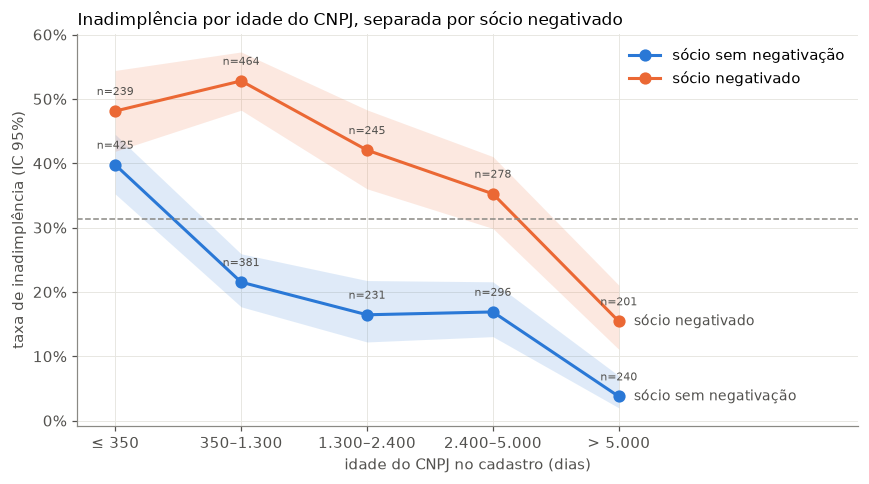

In [31]:
inf_idade = dados.limites(clientes["idade_cnpj"])["inf"].rename("idade_cnpj")
idade_larga = pd.cut(inf_idade, [-1, 349, 1299, 2399, 4999, np.inf],
                     labels=["≤ 350", "350–1.300", "1.300–2.400", "2.400–5.000", "> 5.000"])

fig, ax = plt.subplots(figsize=(8, 4.5))
for valor, nome, cor in [(0, "sócio sem negativação", AZUL), (1, "sócio negativado", LARANJA)]:
    m = clientes["serasa_socio_tem_negativacao"] == valor
    tab = taxa_por_grupo(clientes[m].assign(idade=idade_larga[m]), "idade")
    x = np.arange(len(tab))
    ax.plot(x, tab["taxa"], color=cor, lw=2, marker="o", ms=7, label=nome)
    ax.fill_between(x, tab["ic_inf"], tab["ic_sup"], color=cor, alpha=0.15, lw=0)
    ax.text(x[-1] + 0.12, tab["taxa"].iloc[-1], nome, color=TEXTO, va="center", fontsize=9)
    for xi, (t, n) in enumerate(zip(tab["taxa"], tab["n"])):
        ax.text(xi, t + 0.025, f"n={n}", ha="center", fontsize=7, color=TEXTO)
ax.axhline(TAXA_BASE, color=CINZA, ls="--", lw=1)
ax.set_xticks(x, [str(i) for i in tab.index])
ax.set_xlim(-0.3, len(x) + 0.9)
ax.set_xlabel("idade do CNPJ no cadastro (dias)")
ax.set_ylabel("taxa de inadimplência (IC 95%)")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Inadimplência por idade do CNPJ, separada por sócio negativado", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_interacao_idade_socio.png", dpi=150); plt.show()

**Resposta:** 

**Nenhum sinal anula o outro, mas o peso do sócio negativado muda com a idade da empresa.**

| Idade do CNPJ | Sócio sem negativação | Sócio negativado | Diferença |
|---|---|---|---|
| ≤ 350 dias (até ~1 ano) | 39,8% (n = 425) | 48,1% (n = 239) | +8 pontos |
| 350–1.300 (~1 a 3,5 anos) | 21,5% (n = 381) | 52,8% (n = 464) | +31 pontos |
| 1.300–2.400 (~3,5 a 6,5 anos) | 16,5% (n = 231) | 42,0% (n = 245) | +26 pontos |
| 2.400–5.000 (~6,5 a 14 anos) | 16,9% (n = 296) | 35,3% (n = 278) | +18 pontos |
| > 5.000 (mais de ~14 anos) | 3,8% (n = 240) | 15,4% (n = 201) | +12 pontos |

- **A idade do CNPJ vale para os dois grupos.** Nas duas colunas, o risco cai com a idade: de 40% para 4% entre quem tem sócio sem negativação, e de 48% para 15% entre quem tem sócio negativado. Ter um sócio negativado não apaga o efeito da idade.

- **Empresas com menos de 1 ano são arriscadas de qualquer jeito.** O risco é alto nos dois grupos (40% e 48%), e o sócio negativado acrescenta pouco. Uma leitura possível é que, nessa fase, o que pesa é a própria sobrevivência do negócio, mais do que o histórico de quem o comanda.

- **Depois do primeiro ano, o sócio passa a fazer muita diferença.** Entre 1 e 14 anos de CNPJ, o sócio negativado mais que dobra a taxa. Uma empresa de 1 a 3,5 anos com sócio negativado (52,8%) é tão arriscada quanto uma recém-aberta.

- **Empresas com mais de 14 anos são as mais seguras, mas o sócio ainda importa.** A diferença cai para 12 pontos porque as duas taxas são baixas, mas, em proporção, o sócio negativado multiplica o risco por 4 (de 3,8% para 15,4%).

Os dois sinais devem entrar juntos no modelo, e o efeito de um depende do outro, o que é uma interação.

Os extremos ilustram bem: CNPJ com mais de 14 anos e sócio sem negativação (3,8%, n = 240) é o mais seguro dos dez grupos da tabela, e CNPJ de 1 a 3,5 anos com sócio negativado (52,8%, n = 464) é o mais arriscado dos dez. 

Modelos de árvore captam isso sozinhos. Na regressão logística, vale testar um termo de interação entre idade e sócio negativado, principalmente para separar as empresas com menos de 1 ano, onde o sócio pesa bem menos.


### 6.2 Idade do CNPJ × número de credores

As duas variáveis com mais sinal da base (seção 5.3), agora juntas. O número de credores foi agrupado em 0, 1 e 2+, para cada combinação ter clientes suficientes.

#### **Pergunta:** Uma empresa antiga continua segura quando deve a vários credores?

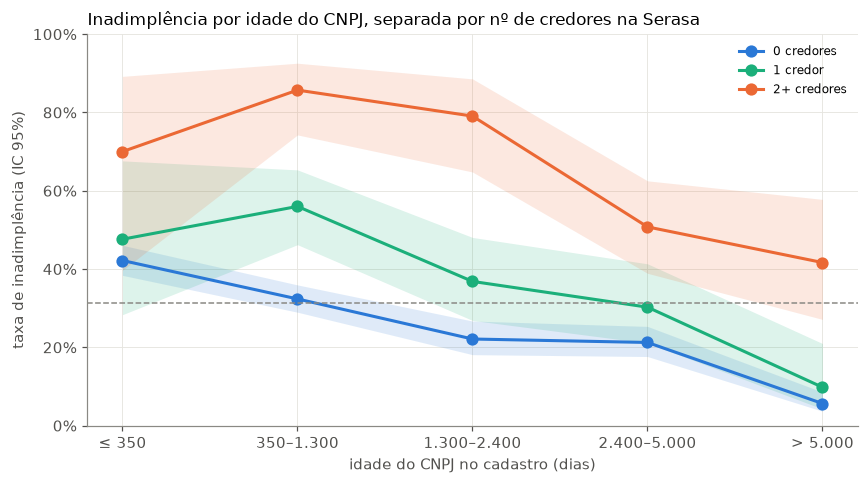

n_credores,0 credores,1 credor,2+ credores
idade_cnpj,,,
≤ 350,"42,2% (n = 633)","47,6% (n = 21)","70,0% (n = 10)"
350–1.300,"32,4% (n = 689)","56,0% (n = 100)","85,7% (n = 56)"
1.300–2.400,"22,1% (n = 357)","36,8% (n = 76)","79,1% (n = 43)"
2.400–5.000,"21,2% (n = 433)","30,3% (n = 76)","50,8% (n = 65)"
> 5.000,"5,6% (n = 354)","9,8% (n = 51)","41,7% (n = 36)"


In [32]:
VERDE = "#1baf7a"  # 3ª cor da paleta categórica, para gráficos com três grupos


def tabela_cruzada(linhas: pd.Series, colunas: pd.Series) -> pd.DataFrame:
    """Taxa de inadimplência e n de cada combinação, como texto "42,2% (n = 633)"."""
    g = clientes.groupby([linhas, colunas], observed=True)["inadimplente"].agg(["mean", "size"])
    texto = g.apply(lambda r: f"{r['mean']:.1%} (n = {int(r['size'])})".replace(".", ","), axis=1)
    return texto.unstack().fillna("—")


def linhas_por_faixa(ax, faixa: pd.Series, grupos, xlabel: str):
    """Uma linha de taxa (com IC 95%) por grupo, ao longo das categorias ordenadas de `faixa`."""
    cats = faixa.cat.categories
    x = np.arange(len(cats))
    for nome, m, cor in grupos:
        tab = taxa_por_grupo(clientes[m].assign(faixa=faixa[m]), "faixa").reindex(cats)
        ax.plot(x, tab["taxa"], color=cor, lw=2, marker="o", ms=7, label=nome)
        ax.fill_between(x, tab["ic_inf"], tab["ic_sup"], color=cor, alpha=0.15, lw=0)
    ax.axhline(TAXA_BASE, color=CINZA, ls="--", lw=1)
    ax.set_xticks(x, [str(c) for c in cats])
    ax.set_xlabel(xlabel)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=8, loc="upper right")


faixa_credores = pd.cut(aux["n_credores"], [-1, 0, 1, np.inf], labels=["0 credores", "1 credor", "2+ credores"])

fig, ax = plt.subplots(figsize=(8, 4.5))
linhas_por_faixa(ax, idade_larga, [
    ("0 credores", faixa_credores == "0 credores", AZUL),
    ("1 credor", faixa_credores == "1 credor", VERDE),
    ("2+ credores", faixa_credores == "2+ credores", LARANJA),
], "idade do CNPJ no cadastro (dias)")
ax.set_ylabel("taxa de inadimplência (IC 95%)")
ax.set_title("Inadimplência por idade do CNPJ, separada por nº de credores na Serasa", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_interacao_idade_credores.png", dpi=150); plt.show()

tabela_cruzada(idade_larga, faixa_credores)

**Resposta:**

**Não. Dever a 2 ou mais credores anula boa parte da proteção que a idade dá.**

- **A idade vale para todos os grupos.** O risco cai com a idade nas três linhas: de 42% para 6% sem credores, e de 70% para 42% com 2 ou mais.

- **Com 2 ou mais credores, nenhuma idade é segura.** Esse grupo fica acima da taxa da base em todas as faixas. Uma empresa com mais de 14 anos e 2+ credores inadimple 41,7% (n = 36), cerca de 7 vezes mais que uma da mesma idade sem credores (5,6%, n = 354). O pior caso é a empresa de 1 a 3,5 anos com 2+ credores: 85,7% (n = 56).

- **Um credor só já pesa, mas menos.** A linha de 1 credor fica no meio. O salto maior é entre 1 e 3,5 anos de CNPJ, de 32% para 56%.

- **Sem credores, a empresa muito nova ainda é arriscada.** Com até 1 ano, a taxa é 42% mesmo sem dívida nenhuma na Serasa. Nessa fase, a idade pesa mais que a Serasa.

**O que isso significa:** os dois sinais se somam e nenhum explica o outro, então os dois devem entrar no modelo. Em proporção, o número de credores pesa mais nas empresas antigas (7 vezes) do que nas novas (1,7 vez, de 42% para 70%), outra interação para testar na regressão logística. Para a política de crédito, 2+ credores é um sinal de alerta em qualquer idade. Os grupos com 2+ credores são pequenos (10 a 65 clientes), então os ICs são largos.


### 6.3 O efeito sobrevive ao controle pela idade?

Nas seções 4.5 e 4.6, natureza jurídica, fonte e segmento mostraram taxas diferentes. Mas a idade do CNPJ é a variável mais forte da base. Se um grupo tem mais empresas novas, ele vai parecer arriscado mesmo que o grupo em si não faça diferença nenhuma. Isso se chama **confundimento**: o efeito de uma variável aparece disfarçado em outra.

Para separar uma coisa da outra, comparamos os grupos **dentro da mesma faixa de idade** (gráfico) e calculamos a **taxa ajustada pela idade** (tabela): a taxa que o grupo teria se tivesse a mesma mistura de idades que a base inteira. Se a diferença entre os grupos se mantém na taxa ajustada, ela é do grupo. Se some, era a idade.

#### **Pergunta:** As diferenças de natureza jurídica, fonte e segmento são reais, ou aparecem só porque esses grupos têm empresas mais novas ou mais velhas?

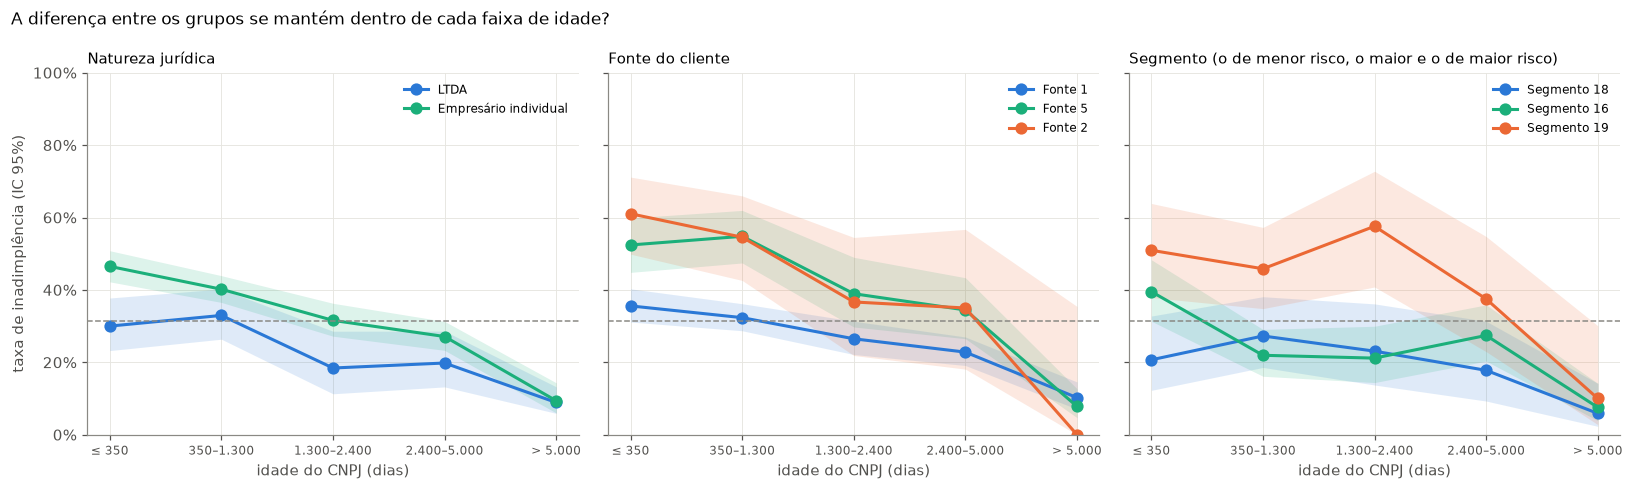

n  \
variável                                           grupo                         
Natureza jurídica                                  LTDA                    736   
                                                   Empresário individual  2249   
Fonte do cliente                                   Fonte 1                2055   
                                                   Fonte 5                 736   
                                                   Fonte 2                 200   
Segmento (o de menor risco, o maior e o de maio... Segmento 18             300   
                                                   Segmento 16             613   
                                                   Segmento 19             210   

                                                                          % com até 1 ano  \
variável                                           grupo                                    
Natureza jurídica                                  LTDA                             0.204   
                                                   Empresário individual            0.229   
Fonte do cliente                                   Fonte 1                          0.202   
                                                   Fonte 5                          0.226   
                                                   Fonte 2                          0.385   
Segmento (o de menor risco, o maior e o de maio... Segmento 18                      0.193   
                                                   Segmento 16                      0.202   
                                                   Segmento 19                      0.252   

                                                                          % com mais de 14 anos  \
variável                                           grupo                                          
Natureza jurídica                                  LTDA                                   0.321   
                                                   Empresário individual                  0.085   
Fonte do cliente                                   Fonte 1                                0.124   
                                                   Fonte 5                                0.243   
                                                   Fonte 2                                0.035   
Segmento (o de menor risco, o maior e o de maio... Segmento 18                            0.227   
                                                   Segmento 16                            0.173   
                                                   Segmento 19                            0.095   

                                                                          taxa bruta  \
variável                                           grupo                               
Natureza jurídica                                  LTDA                        0.213   
                                                   Empresário individual       0.347   
Fonte do cliente                                   Fonte 1                     0.273   
                                                   Fonte 5                     0.375   
                                                   Fonte 2                     0.505   
Segmento (o de menor risco, o maior e o de maio... Segmento 18                 0.190   
                                                   Segmento 16                 0.240   
                                                   Segmento 19                 0.443   

                                                                          taxa ajustada pela idade  
variável                                           grupo                                            
Natureza jurídica                                  LTDA                                      0.239  
                                                   Empresário individual                     0.332  
Fonte do cliente                                 

In [33]:
natureza_curta = clientes["natureza_juridica"].map({
    "206-2 - Sociedade Empresária Limitada": "LTDA",
    "213-5 - Empresário (Individual)": "Empresário individual",
})
pesos_idade = idade_larga.value_counts(normalize=True)


def controle_por_idade(serie: pd.Series, grupos: list) -> pd.DataFrame:
    """Mistura de idades, taxa bruta e taxa ajustada pela idade de cada grupo."""
    linhas = []
    for g in grupos:
        m = serie == g
        taxa_faixa = clientes.loc[m, "inadimplente"].groupby(idade_larga[m], observed=False).mean()
        linhas.append({
            "grupo": g, "n": int(m.sum()),
            "% com até 1 ano": (idade_larga[m] == "≤ 350").mean(),
            "% com mais de 14 anos": (idade_larga[m] == "> 5.000").mean(),
            "taxa bruta": clientes.loc[m, "inadimplente"].mean(),
            "taxa ajustada pela idade": (taxa_faixa * pesos_idade).sum(min_count=len(pesos_idade)),
        })
    return pd.DataFrame(linhas).set_index("grupo")


paineis = [
    ("Natureza jurídica", natureza_curta, ["LTDA", "Empresário individual"]),
    ("Fonte do cliente", clientes["fonte_cliente"], ["Fonte 1", "Fonte 5", "Fonte 2"]),
    ("Segmento (o de menor risco, o maior e o de maior risco)", clientes["segmento_cliente"], ["Segmento 18", "Segmento 16", "Segmento 19"]),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (titulo, serie, grupos) in zip(axes, paineis):
    linhas_por_faixa(ax, idade_larga, [(g, serie == g, cor) for g, cor in zip(grupos, [AZUL, VERDE, LARANJA])],
                     "idade do CNPJ (dias)")
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("taxa de inadimplência (IC 95%)")
fig.suptitle("A diferença entre os grupos se mantém dentro de cada faixa de idade?", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_controle_idade.png", dpi=150); plt.show()

pd.concat({titulo: controle_por_idade(serie, grupos) for titulo, serie, grupos in paineis}, names=["variável", "grupo"])

**Resposta:**

**As diferenças são reais nos três casos, mas a idade distorce a comparação da natureza jurídica e da fonte.** Lendo a tabela: as duas colunas de "%" mostram a mistura de idades de cada grupo, e a taxa ajustada é a que o grupo teria com a mesma mistura de idades da base.

- **Natureza jurídica: cerca de 1/3 da diferença era idade.** As LTDAs são bem mais antigas: 32% têm mais de 14 anos, contra 8,5% dos empresários individuais. Sem ajuste, a diferença é de 13 pontos (21,3% vs 34,7%). Com ajuste, cai para 9 pontos (23,9% vs 33,2%). O empresário individual continua mais arriscado, mas só até ~14 anos de CNPJ: acima disso, os dois ficam iguais (~9%).

- **Fonte: a comparação sem ajuste engana.** A Fonte 2 tem muitas empresas novas (38% com até 1 ano, contra 20% da Fonte 1), e por isso parecia ainda pior. Ajustada, ela cai de 50,5% para 41,4%, mas continua bem acima da Fonte 1 (27,1%). Já a Fonte 5 tem o problema oposto: tem muitas empresas antigas (24% com mais de 14 anos), o que **esconde** o risco dela. Ajustada, ela sobe de 37,5% para 41,0%, praticamente igual à Fonte 2. Ou seja, com a mesma idade, a Fonte 5 é tão arriscada quanto a Fonte 2, e ela tem 736 clientes, contra 200 da Fonte 2.

- **Segmento: a idade não explica nada.** Os segmentos têm misturas de idade parecidas, e as taxas quase não mudam com o ajuste (19,0% → 20,2% no 18, 44,3% → 42,0% no 19). O Segmento 19 fica acima dos outros em quase todas as faixas.

- **Acima de 14 anos, todo mundo converge.** Nos três painéis, as linhas se encontram em ~5% a 10% na última faixa. Para empresas muito antigas, natureza, fonte e segmento quase não importam.

**O que isso significa:** natureza jurídica, fonte e segmento trazem informação própria, além da idade, e devem entrar no modelo junto com ela. O achado mais importante é a Fonte 5: a análise do 4.5 a subestimou, e ela pesa tanto quanto a Fonte 2. O ajuste controla só pela idade. Outras variáveis ainda podem explicar parte dessas diferenças, e é para isso que o modelo existe.


### 6.4 Número de credores × sócio negativado

Os dois sinais mais fortes da Serasa juntos: as dívidas da empresa e o histórico do sócio.

#### **Pergunta:** O sócio negativado ainda pesa quando a empresa já deve a vários credores?

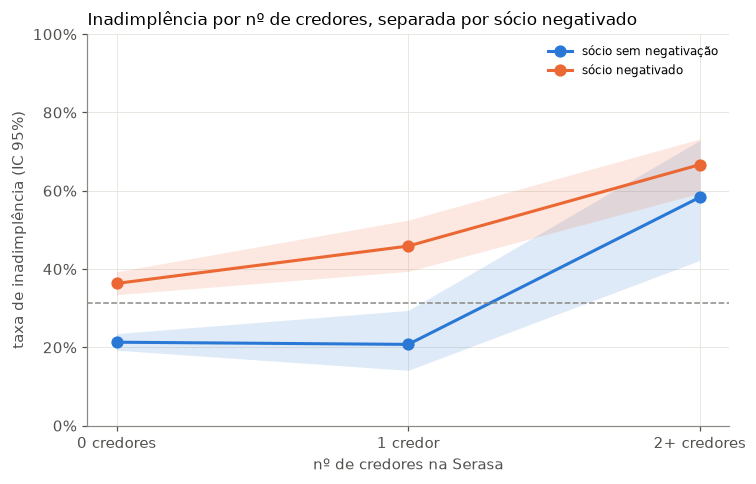

serasa_socio_tem_negativacao,sócio sem negativação,sócio negativado
n_credores,,
0 credores,"21,3% (n = 1431)","36,3% (n = 1035)"
1 credor,"20,8% (n = 106)","45,9% (n = 218)"
2+ credores,"58,3% (n = 36)","66,7% (n = 174)"


In [34]:
fig, ax = plt.subplots(figsize=(7, 4.5))
linhas_por_faixa(ax, faixa_credores, [
    ("sócio sem negativação", clientes["serasa_socio_tem_negativacao"] == 0, AZUL),
    ("sócio negativado", clientes["serasa_socio_tem_negativacao"] == 1, LARANJA),
], "nº de credores na Serasa")
ax.set_ylabel("taxa de inadimplência (IC 95%)")
ax.set_title("Inadimplência por nº de credores, separada por sócio negativado", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_interacao_credores_socio.png", dpi=150); plt.show()

socio = clientes["serasa_socio_tem_negativacao"].map({0: "sócio sem negativação", 1: "sócio negativado"})
tabela_cruzada(faixa_credores, socio.astype(pd.CategoricalDtype(["sócio sem negativação", "sócio negativado"])))

**Resposta:**

**Depende do número de credores. Com até 1 credor, o sócio é o que mais pesa. Com 2 ou mais, o risco já é alto de qualquer jeito.**

- **Com sócio sem negativação, ter 1 credor não muda nada:** 21,3% sem credores e 20,8% com 1 (n = 106). Com sócio negativado, o mesmo credor faz a taxa subir de 36,3% para 45,9%. Uma leitura possível é que uma dívida isolada pode ser só um imprevisto, mas, somada a um sócio negativado, indica um padrão de dificuldade financeira.

- **Sem credores, o sócio negativado sozinho já eleva o risco:** 36,3% contra 21,3%.

- **Com 2 ou mais credores, o sócio acrescenta pouco:** 58,3% contra 66,7%, com ICs que se sobrepõem, porque o grupo sem negativação tem só 36 clientes.

- **O grupo "limpo" é grande:** sem credores e com sócio sem negativação há 1.431 clientes (48% da base), com 21,3% de inadimplência, 10 pontos abaixo da média.

**O que isso significa:** os dois sinais da Serasa se sobrepõem só em parte, e o efeito do primeiro credor depende do sócio, mais uma interação. Uma feature combinada ("sem nenhum registro na Serasa": sem credores e com sócio sem negativação) pode ser uma forma simples de capturar isso na engenharia de features.


## 7. Tempo

A tabela de clientes não tem data de cadastro (pergunta em aberto do notebook 1), então o único eixo de tempo são as entregas dos pedidos. Aqui olhamos só a cobertura no tempo e a taxa por safra.

#### **Pergunta:** Como os pedidos se distribuem no tempo?

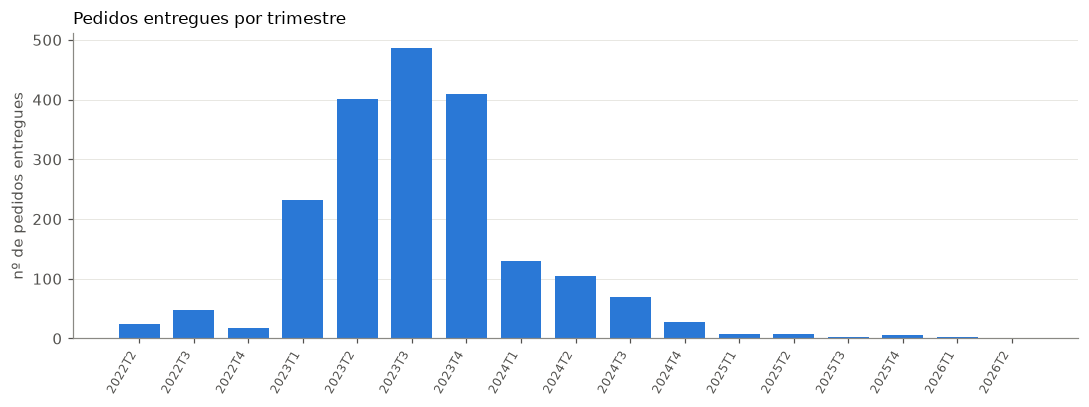

In [35]:
por_trimestre = pedidos.set_index("data_entrega").resample("QE").size()
rotulos_tri = [f"{d.year}T{d.quarter}" for d in por_trimestre.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(por_trimestre)), por_trimestre.values, color=AZUL, width=0.75)
ax.set_xticks(range(len(por_trimestre)), rotulos_tri, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("nº de pedidos entregues")
ax.grid(axis="x", visible=False)
ax.set_title("Pedidos entregues por trimestre", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "eda_pedidos_trimestre.png", dpi=150); plt.show()

**Resposta:**

Os pedidos se concentram entre 2023T1 e 2023T4 (77% do total). A partir de 2025 a operação quase some (menos de 10 pedidos por trimestre). Isso pode ser corte de amostragem da Praso ou mudança no negócio. De qualquer forma, o comportamental é essencialmente um retrato de 2023.

#### **Pergunta:** A taxa de inadimplência muda conforme a safra?

Safra = trimestre do primeiro pedido do cliente, que é o mais perto de uma data de entrada que temos.

Vale só para os 664 clientes com pedidos. Trimestres com menos de 30 clientes foram juntados por ano: todos os de 2022 viraram "2022 (outros tri.)", com 45 clientes, e todos os de 2024, "2024 (outros tri.)", com 46.

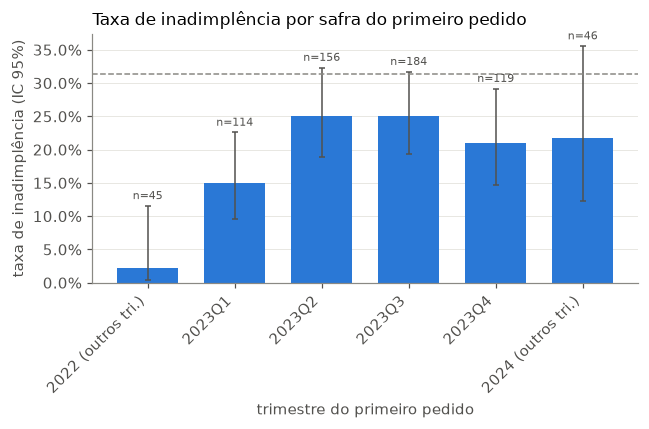

In [36]:
primeiro = pedidos.groupby("id_cliente")["data_entrega"].min()
safra = clientes["id_cliente"].map(primeiro).dt.to_period("Q").astype(str)
com_pedido = clientes[safra.notna() & (safra != "NaT")].assign(safra=safra)
cont = com_pedido["safra"].value_counts()
ano = com_pedido["safra"].str[:4]
com_pedido["safra"] = com_pedido["safra"].where(com_pedido["safra"].map(cont) >= 30, ano + " (outros tri.)")
cont = com_pedido["safra"].value_counts()
com_pedido["safra"] = com_pedido["safra"].where(com_pedido["safra"].map(cont) >= 30, "outros (< 30)")
tab = taxa_por_grupo(com_pedido, "safra").sort_index()
plot_taxa(tab, "Taxa de inadimplência por safra do primeiro pedido", "eda_safra.png", xlabel="trimestre do primeiro pedido")

**Resposta:** 

Sim, e muito. Quem fez o primeiro pedido em **2022** quase não inadimpliu: **2,2%**, ou seja, 1 de 45. As safras de 2023 ficam entre 15% e 25%.

Pode ser seleção dos primeiros clientes, mudança na política de crédito ou na forma de medir o alvo. Os dados não permitem decidir, e a pergunta deve ir para a Praso. Futuramente, se o desempenho variar por safra, vale testar uma validação temporal além da estratificada.

## 8. Qualidade: o que surgiu na EDA

Checagens de coerência entre colunas que a limpeza não cobre: valores fora do esperado, grafias duplicadas, informações da Serasa que se contradizem e pedidos com nulo ou repetidos. Só contagens.

In [37]:
lim_nota = dados.limites(clientes["google_maps_avaliacao"].dropna())
nome_norm = clientes["municipio"].str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii").str.upper().str.strip()
negativado = clientes["serasa_contagem_negativacoes"] > 0
pd.Series({
    "nota do Google Maps fora de 0–5": int(((lim_nota["inf"] < 0) | (lim_nota["sup"] > 5)).sum()),
    "municípios que se fundem ao normalizar grafia": clientes["municipio"].nunique() - nome_norm.nunique(),
    "negativações > 0 e sem credores listados": int((negativado & ~aux["tem_credores_serasa"]).sum()),
    "credores listados e 0 negativações": int((~negativado & aux["tem_credores_serasa"]).sum()),
    "pedidos com nulo em valor ou atraso": int(dados.pedidos_com_nulo(pedidos).sum()),
    "possíveis pedidos repetidos (mesmo cliente, data e faixa de valor)": int(pedidos.duplicated(["id_cliente", "data_entrega", "valor"]).sum()),
}, name="ocorrências").to_frame()

,ocorrências
nota do Google Maps fora de 0–5,0
municípios que se fundem ao normalizar grafia,0
negativações > 0 e sem credores listados,97
credores listados e 0 negativações,0
pedidos com nulo em valor ou atraso,2
"possíveis pedidos repetidos (mesmo cliente, data e faixa de valor)",54


**Resposta:** - **97 clientes têm negativação mas nenhum credor listado.** Os credores podem vir de outra fonte, ou ser só os 5 mais recentes. Vale perguntar à Praso, porque isso afeta como as features interpretam `serasa_credores` nulo.
- **54 pedidos podem ser repetidos** (mesmo cliente, mesma data, mesma faixa de valor). Podem ser pedidos legítimos no mesmo dia, mas é preciso decidir isso antes de contar pedidos.
- **2 pedidos têm nulo** (um sem `valor`, outro sem `atraso`). A limpeza os mantém na base, e o tratamento fica para as agregações dos pedidos.
- **Sem problemas:** a nota do Google Maps fica em 0–5, não há grafias duplicadas de município e não há credores listados sem negativação.

## 9. Resumo

3.000 clientes do CE, com 31,3% de inadimplência. 664 deles (22%) têm 1.977 pedidos, 77% em 2023.

**Conclusões principais:**

1. **O risco vem de três fontes: a maturidade da empresa, o histórico financeiro e o tipo de negócio.** A idade do CNPJ é o sinal mais forte da base (de 57% para 6%, MI 0,038). Em seguida vêm a Serasa, com o número de credores (de 28% para 72%) e o sócio negativado (42% contra 22%), e o perfil do negócio: segmento (de 19% a 44% entre os grandes), fonte e natureza jurídica. Presença no iFood ou no Google Maps e protestos quase não informam. O município também informa pouco: agrupado por região, Fortaleza (33,2%) inadimple mais que a região metropolitana (27,2%), mas a região sozinha tem AUC de só 0,518.

2. **Nenhuma variável resolve sozinha, mas juntas separam muito bem.** A melhor variável sozinha, a idade do CNPJ, tem ROC-AUC de 0,639, e a maior MI é 0,038, de um máximo de ~0,62. Combinando só duas variáveis, a taxa vai de 3,8% (CNPJ com mais de 14 anos e sócio sem negativação, n = 240) a 85,7% (CNPJ de 1 a 3,5 anos com 2 ou mais credores, n = 56). O modelo vai depender da combinação.

3. **Os sinais interagem: o peso de um depende do outro.** O sócio negativado quase não muda o risco de empresas com menos de 1 ano, que já é alto, mas dobra a taxa entre 1 e 14 anos. Ter 2 ou mais credores anula a proteção da idade: uma empresa com mais de 14 anos nessa situação inadimple 41,7%, contra 5,6% sem credores. E 1 credor só pesa quando o sócio também está negativado: nesse caso a taxa vai de 36% para 46%, e com o sócio sem negativação fica em 21%.

4. **Algumas comparações diretas enganam.** Ajustada pela idade, a Fonte 5 é tão arriscada quanto a Fonte 2 (~41%), e não intermediária como parecia (37,5%). Cerca de 1/3 da diferença entre empresário individual e LTDA era só idade, porque as LTDAs são mais antigas. No CNAE, os níveis agregados escondem diferenças: o grupo 77.7 (25,6%) mistura uma classe com 21,8% e outra com 39,8%.

5. **Algumas variáveis repetem a mesma informação.** Número de credores e negativações (ρ = 0,90) medem quase a mesma coisa, assim como os três níveis do CNAE (V de 0,89 a 0,94). O segmento da Praso, por outro lado, não é um recorte do CNAE (V = 0,58) e tem mais sinal que ele (V = 0,19 contra 0,11–0,15).

6. **No histórico de pedidos, o atraso é o melhor sinal, mas o histórico vem cortado.** Quem nunca atrasou inadimple 7,1%, e com pior atraso a partir de 5 dias, 33% a 50%. Nos 664 clientes com pedidos, o pior atraso sozinho (AUC 0,677) ordena melhor que a idade do CNPJ (0,647). Pedidos de maior valor também indicam menos risco (de 24% até R$ 250 para 9% acima de R$ 1.000). Mas a base traz no máximo 3 pedidos por cliente, e 11 dos 13 clientes com menos de 3 são inadimplentes, o que sugere que o histórico inclui o período depois do calote.

7. **A maior incerteza está no alvo, não nas variáveis.** Quem tem pedidos inadimple bem menos (20,8% contra 34,3%), e o perfil de cadastro não explica a diferença. A base não tem nenhuma data, nem de cadastro, nem de observação do alvo, e a safra de 2022 tem só 1 inadimplente em 45. Até a Praso responder às perguntas 1, 2 e 7, não dá para garantir que o histórico de pedidos é anterior ao alvo.

**Hipóteses**

| # | Hipótese | Veredito | Evidência |
|---|---|---|---|
| H1 | Idade do CNPJ reduz a inadimplência | Confirmada | 57% → 6%; degraus em ~1.600 e ~5.000 dias; maior MI (0,038) |
| H2 | Capital social reduz a inadimplência | Parcial | ~40% até R$ 1.500 → 21–30% de R$ 8.000 a R$ 100.000; MI 0,010; parte do sinal é compartilhada com LTDA |
| H3 | Registro na Serasa aumenta a inadimplência | Confirmada | Credores: 28% → 72%; negativações: 28% → 49%; sócio negativado: 42% vs 22%; protestos: fraco |
| H4 | Estar nas plataformas reduz a inadimplência | Fraca | 27% vs 32% (iFood), 26% vs 32% (Maps); ICs quase se tocam; MI 0,001 |
| H5 | Mais avaliações reduzem a inadimplência | Parcial | 0 de 40 com > 750 avaliações no Google Maps; iFood sem padrão; só 7% da base está no Maps |
| H6 | Empresário individual inadimple mais que LTDA | Confirmada | 34,7% vs 21,3% |
| H7 | A fonte de aquisição importa | Confirmada | Fonte 2: 50,5%; Fonte 5: 37,5%; Fonte 1: 27,3%. Ajustadas pela idade, as Fontes 2 e 5 ficam iguais (~41%) |
| H8 | Segmentos e CNAE têm riscos diferentes | Confirmada | Segmento: 19% a 44% entre os segmentos com mais de 100 clientes; CNAE fora das 3 divisões principais: 46,5% |
| H9 | Fortaleza difere do interior | Parcial | Município a município, não; por região, Fortaleza (33,2%) inadimple mais que a região metropolitana (27,2%). Sinal fraco: AUC 0,518 |
| H10 | Quem atrasa mais inadimple mais | Confirmada | Pior atraso: 7,1% sem atraso → 33–50% a partir de 5 dias; AUC 0,677 nos 664 com pedidos, acima da idade do CNPJ (0,647) |

**O que isso significa para o projeto:**

- *Features (sugestões, não decisões):* idade do CNPJ, testando marcos em ~1.600 e ~5.000 dias; número de credores **ou** negativações, não os dois; sócio negativado; uma flag "sem nenhum registro na Serasa" (48% da base, 21,3% de inadimplência); uma flag "deve a fornecedor de Alimentos e Bebidas ou Distribuição" (65%); segmento, fonte e natureza jurídica, com categorias raras agrupadas; classe do CNAE agrupada ou *target encoding* dentro do `Pipeline`. Plataformas, município e região têm prioridade baixa.

- *Modelo de aplicação:* a linha de base a superar é o ROC-AUC da idade do CNPJ sozinha (0,639). A regressão logística precisa de termos de interação (idade × sócio e idade × credores) e de cuidado com as redundâncias; os modelos de árvore captam isso sozinhos. Sem data, a divisão treino/teste tem de ser aleatória e estratificada.

- *Modelo comportamental:* o ganho deve ser medido nos mesmos 664 clientes, comparando com o modelo de aplicação, e conferido por safra. Os melhores candidatos do histórico são o pior atraso (AUC 0,677) e a proporção de pedidos com atraso. O número de pedidos não deve ser usado: a base corta em 3, e ter menos de 3 indica o próprio calote. Os 2 pedidos com nulo e os 54 possivelmente repetidos precisam de decisão antes das agregações.

- *Política de crédito:* as combinações já indicam faixas naturais de risco. Uma empresa com mais de 14 anos e sócio sem negativação é quase sem risco (3,8%), e 2 ou mais credores são um alerta em qualquer idade. Como os clientes de maior risco fazem pedidos menores (24% de inadimplência até R$ 250, contra 9% acima de R$ 1.000), um limite de crédito por faixa de risco pode reduzir a perda sem barrar tantos clientes. Os cortes devem sair do modelo, não da EDA.

**Perguntas em aberto (para a Praso ou o professor)**
1. Existe data de cadastro do cliente, ou da observação da inadimplência? Os dados da Serasa e das plataformas são do momento do cadastro?
2. Como o alvo foi definido, principalmente para os 78% de clientes sem pedidos?
3. Por que a safra de 2022 tem só 2% de inadimplência?
4. A Praso mudou algum critério das fontes de aquisição ao longo do tempo?
5. Por que 97 clientes têm negativação e nenhum credor listado?
6. Os 54 pedidos possivelmente repetidos são pedidos distintos?
7. Por que cada cliente tem no máximo 3 pedidos na base? São os primeiros, os últimos ou uma amostra? E por que quem tem menos de 3 é quase sempre inadimplente?
